# Deconvolving standard Visium spots with the heart atlas

## Motivation

A spot of a standard Visium slide is 55 µm wide. In the myocardium it covers a few cardiomyocytes together with the
capillaries, pericytes, fibroblasts and immune cells between them, so its expression profile is a mixture.
Deconvolution estimates, for every spot, the proportion of each cell type from the expression profiles of a
single-cell reference. Many methods exist, and on the same spots they can give rather different answers, so before
using the proportions we need to know which method to trust.

In this notebook we build the reference from the heart atlas and deconvolve the Visium cohort with a simple
baseline, non-negative least squares (NNLS). We then construct spots of *known* composition from Visium HD and
score NNLS and six published methods against them, look at how the methods differ on real sections (ED6 c, g, h),
and finally use the proportions for two questions about the chambers of the heart: do the chamber marker genes of
cardiomyocytes from the atlas hold in cardiomyocyte-dominant spots (Fig 3 c), and do pericyte-rich spots of the
atria carry the atrial-pericyte signature (ED8 b–c)?

## Dataset

| object | content | fields used here |
|---|---|---|
| heart atlas `AnnData` | 1.46 million nuclei of the snRNA atlas | `layers["counts"]`, `obs["Final Level 3_harmonized"]` |
| Level-3 signatures | mean expression of every gene in the 23 Level-3 types of the atlas (table of the cell-typing pipeline) | genes × types |
| standard Visium, Noseda cohort | 16 slides of atria and ventricles (Space Ranger outputs), 11 of them with spot positions and H&E image | counts, `obsm["spatial"]`, `uns["spatial"]` |
| standard Visium, Kanemaru et al. 2023 | one `AnnData` per chamber (LA, RA, LV, RV), log-normalised, with the authors' cell2location result | `X`, `obsm["prop"]`, `obs["donor"]` |
| Visium HD decode of one section | transcripts and the Level-3 type of every 2 µm pixel (FICTURE) | `X`, `Y`, `gene`, `Count`; `K1` |
| per-spot outputs of six methods | proportions of cell2location, stereoscope, spotiphy, UCASpatial, RCTD and SPOTlight on the simulated spots and on the 11 slides | spots × types |
| two curated gene tables (`resources/deconvolution/`) | atrial and ventricular cardiomyocyte genes of the atlas; the 30-gene atrial-pericyte signature | gene, direction |

Six of the seven methods need a GPU or R and run as cluster jobs; we load their per-spot outputs. Everything else
is computed here. The analysis steps live in `hhca.tl` and the figure panels in `hhca.pl`; the command-line scripts
in `scripts/deconvolution/` and `figures/` call the same functions.

## Environment setup

We load the packages and set the scanpy defaults; `style.notebook()` gives the plots of this notebook the font and
open axes of the figure panels. All result paths are relative to the repository root, so we work from there.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import json
import os
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import squidpy as sq

import hhca
from hhca.config import load_config
from hhca.pl import style

sc.settings.verbosity = 0
sc.settings.set_figure_params(dpi=80, facecolor="white", frameon=False)
style.notebook()
np.random.seed(0)
os.chdir(hhca.REPO)

Every parameter of the analysis is set in `config/deconvolution.yaml`: slides, filters, gene lists and thresholds.
We read the file once. The table lists the Noseda slides: 11 have spot positions and are deconvolved by all
methods, five come as count matrices only and are deconvolved by NNLS.

In [2]:
cfg = load_config("deconvolution")
inputs = cfg["inputs"]
slides_cfg = cfg["slides"]
noseda = f"{inputs['root']}/{inputs['noseda']}"
kanemaru_dir = f"{inputs['root']}/{inputs['kanemaru']}"
results = "results/deconvolution"
benchmark = slides_cfg["benchmark"]
all_slides = benchmark + slides_cfg["nnls_only"]

slide_table = pd.DataFrame(index=all_slides)
slide_table["spot positions"] = slide_table.index.isin(benchmark)
region_of_slide = pd.Series(slides_cfg["fig3c_region"]).reindex(all_slides)
slide_table["chamber region"] = region_of_slide.fillna("ventricle, not assigned")
slide_table

,spot positions,chamber region
HHH1-LA,True,LA
HHH2-LV-endo-1,True,LV
HHH4-RA2,True,RA
HHH4-RV2,True,RV
A17-AH1-C1,True,"ventricle, not assigned"
A18-AH2-D1,True,"ventricle, not assigned"
HHH2-D1,True,"ventricle, not assigned"
HHH2-LV-endo-2,True,LV
HHH4-A1,True,"ventricle, not assigned"
HHH5-B1,True,"ventricle, not assigned"


## Loading data

### The single-cell reference

All methods learn the expression profile of a cell type from the same reference. The atlas holds 1.46 million
nuclei, far more than a method needs, and its cell types differ in size by three orders of magnitude.
`hhca.tl.sample_reference` draws at most 1,000 nuclei per Level-3 type and reads their raw counts from the atlas
file.

In [3]:
reference_cfg = cfg["reference"]
reference = hhca.tl.sample_reference(
    inputs["atlas"],
    label=reference_cfg["label"],
    n_per_type=reference_cfg["n_per_type"],
    seed=reference_cfg["seed"],
    exclude=reference_cfg["exclude"],
    obs_columns=reference_cfg["obs_columns"],
)
reference

AnnData object with n_obs × n_vars = 21148 × 36601
    obs: 'cell_type_L3', 'sex', 'tissue_general', 'donor_id', 'development_stage', 'dataset', 'assay', 'suspension_type', 'manner_of_death'
    uns: 'n_cells'

`scripts/deconvolution/build_reference.py` writes this reference for the other six methods. Most types reach 1,000
nuclei; the rare ones contribute all the nuclei they have.

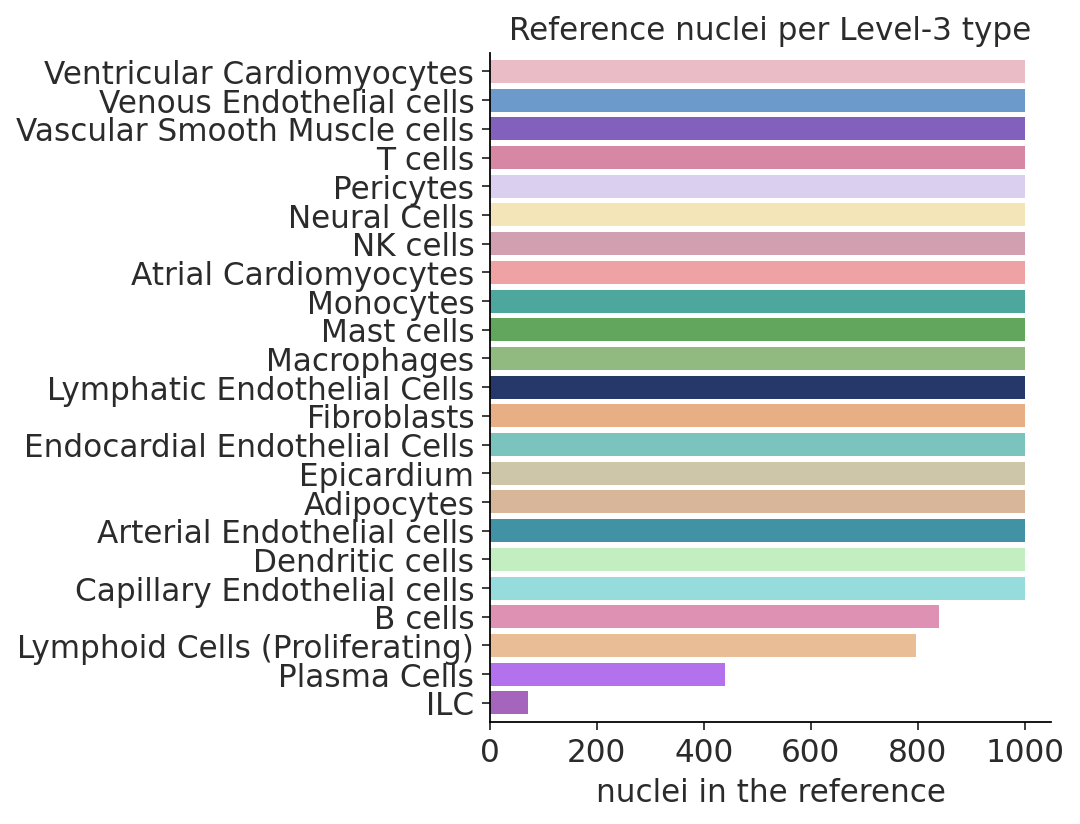

In [4]:
n_nuclei = pd.Series(reference.uns["n_cells"]).sort_values()
colours = [style.CT[cell_type] for cell_type in n_nuclei.index]
ax = n_nuclei.plot.barh(color=colours, width=0.8, figsize=(4.5, 5.5))
ax.set(xlabel="nuclei in the reference", title="Reference nuclei per Level-3 type")
plt.show()

### A standard Visium section

We walk through each step on one section, `HHH2-LV-endo-1` from the left-ventricular wall near the endocardium,
and then run it on the cohort. `sq.read.visium` reads the Space Ranger output with the H&E image. As for every
slide of the pipeline, we keep genes detected in at least 3 spots and spots with at least 200 counts.

In [5]:
qc = cfg["qc"]
figures_cfg = cfg["figures"]
section = figures_cfg["ed6_slide"]
adata = sq.read.visium(f"{noseda}/{section}", library_id=section)
adata.var_names_make_unique()
sc.pp.filter_genes(adata, min_cells=qc["min_cells_per_gene"])
sc.pp.filter_cells(adata, min_counts=qc["min_counts_per_spot"])
adata

AnnData object with n_obs × n_vars = 1963 × 15113
    obs: 'in_tissue', 'array_row', 'array_col', 'n_counts'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells'
    uns: 'spatial'
    obsm: 'spatial'

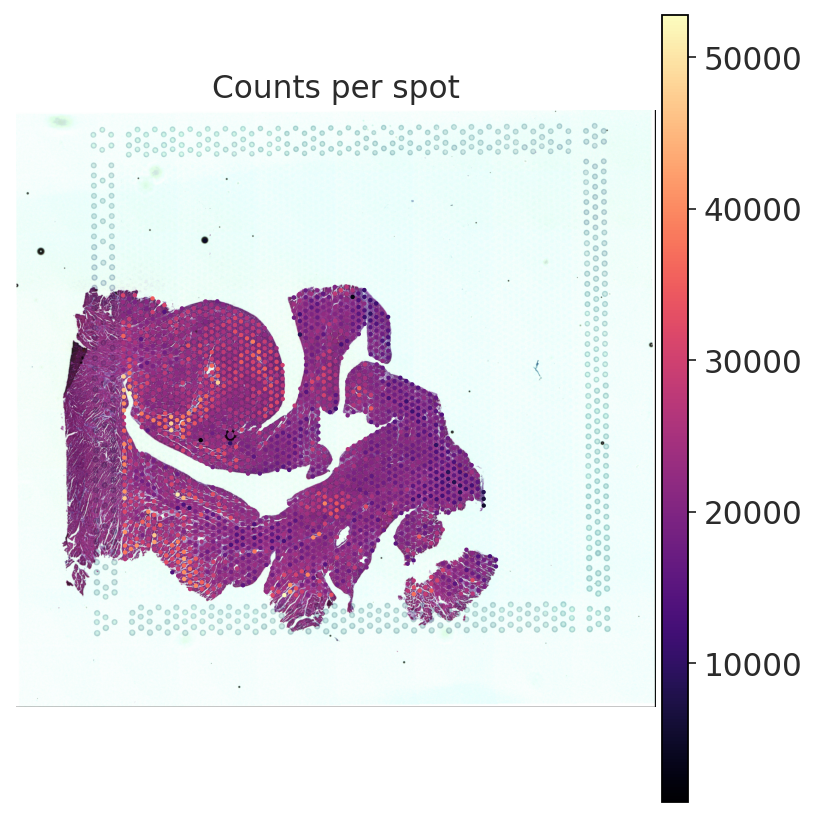

In [6]:
sq.pl.spatial_scatter(
    adata, color="n_counts", library_id=section, cmap=style.SEQUENTIAL, figsize=(5, 5), title="Counts per spot"
)

### The gene panel of cell2location and stereoscope

Two of the methods fit a model per gene and are run on a panel instead of all genes. `hhca.tl.gene_panel` takes
the 3,000 most variable genes of the reference among the genes measured on all 11 slides, and adds cardiac marker
genes that must not be lost. The gene lists of the slides were written by `scripts/deconvolution/prep_inputs.py`.

In [7]:
markers = cfg["markers"]
cardiac_markers = markers["cardiac"]
panel_cfg = cfg["methods"]["gene_panel"]
gene_lists = [Path(f"{results}/inputs/{name}/genes.txt").read_text().split() for name in benchmark]
panel = hhca.tl.gene_panel(
    reference,
    gene_lists,
    n_hvg=panel_cfg["n_hvg"],
    markers=cardiac_markers + markers["lymphatic"],
    min_cells=panel_cfg["min_cells"],
)
print(f"{len(panel):,} genes in the panel")

rows = []
for genes in markers.values():
    rows.append({"markers in the panel": len(set(genes) & set(panel)), "listed": len(genes)})
pd.DataFrame(rows, index=list(markers))

3,001 genes in the panel


,markers in the panel,listed
cardiac,42,52
lymphatic,4,4


The reference holds 21,148 nuclei of 23 Level-3 types: 19 types with 1,000 nuclei and four smaller ones (B cells
839, proliferating lymphoid cells 797, plasma cells 440, ILC 72). Our section has 1,963 spots and 15,113 genes. The
gene panel has 3,001 genes; it contains 42 of the 52 cardiac markers and the four lymphatic markers.

## Deconvolution by non-negative least squares

The simplest model of a spot is a sum: its expression is the expression signature of each cell type, weighted by
how much of that type the spot contains. As signatures we use the mean expression of the 23 Level-3 types in the
atlas, the same profiles that define the cell types on Visium HD.

In [8]:
signatures = pd.read_csv(inputs["pseudobulk_L3"], sep="\t", index_col=0)
cell_types = list(signatures.columns)
print(f"{signatures.shape[0]:,} genes x {signatures.shape[1]} cell types")
shown_genes = ["MYH7", "NPPA", "DCN", "RGS5"]
shown_types = ["Ventricular Cardiomyocytes", "Atrial Cardiomyocytes", "Fibroblasts", "Pericytes"]
signatures.loc[shown_genes, shown_types].round(2)

14,016 genes x 23 cell types


,Ventricular Cardiomyocytes,Atrial Cardiomyocytes,Fibroblasts,Pericytes
gene,,,,
MYH7,10.49,2.20,0.51,1.47
NPPA,0.17,13.91,0.31,0.34
DCN,0.18,0.20,14.54,2.27
RGS5,0.09,0.10,0.09,11.62


Most genes say little about the mixture. `hhca.tl.signature_genes` keeps the 2,000 genes whose signature varies
most across the cell types (coefficient of variation) and the cardiac markers, among the genes of the section.

In [9]:
n_top_genes = cfg["methods"]["NNLS"]["n_top_genes"]
fit_genes = hhca.tl.signature_genes(signatures, adata.var_names, n_top_genes, cardiac_markers)
n_markers = len(set(fit_genes) & set(cardiac_markers))
print(f"{len(fit_genes):,} genes, {n_markers} of the {len(cardiac_markers)} markers among them")

2,006 genes, 49 of the 52 markers among them


`hhca.tl.nnls_deconvolution` normalises every spot to 10,000 counts and fits it as a non-negative mixture of the
signatures on these genes. A cardiomyocyte holds far more mRNA than a lymphocyte, so the weights are converted to
the share of the spot's mRNA that each type contributes, and these shares sum to 1. The result is stored in
`adata.obsm["NNLS"]`.

In [10]:
hhca.tl.nnls_deconvolution(adata, signatures, n_top_genes, cardiac_markers)
section_mean = adata.obsm["NNLS"].mean().sort_values(ascending=False)
section_mean.head(6).round(3).to_frame("mean proportion")

,mean proportion
Ventricular Cardiomyocytes,0.538
Arterial Endothelial cells,0.082
T cells,0.072
Lymphatic Endothelial Cells,0.070
Mast cells,0.058
Dendritic cells,0.038


For a first look we colour every spot by its dominant cell type, in the atlas palette of the deconvolution
panels, and show the proportion of two cell types on the tissue.

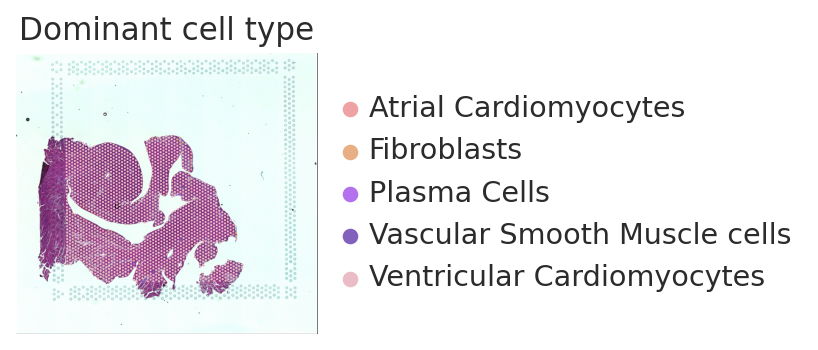

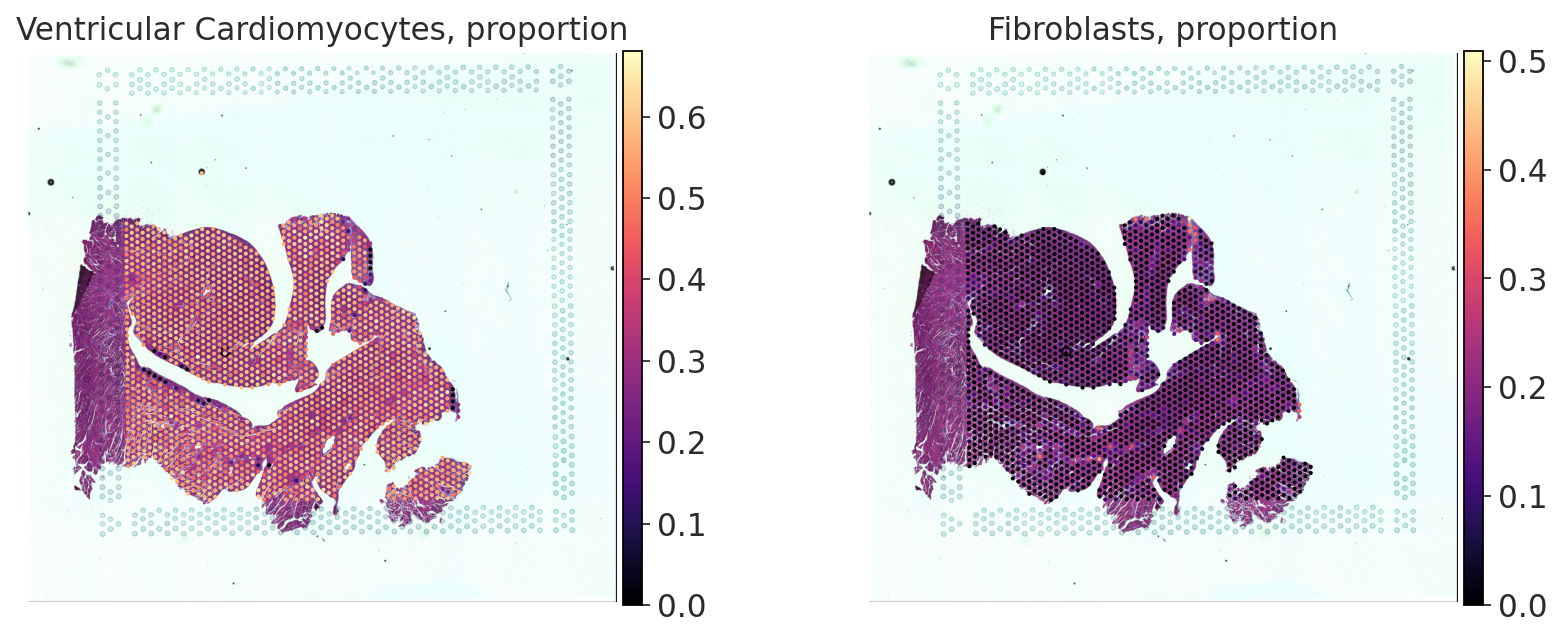

In [11]:
adata.obs["dominant_L3"] = adata.obsm["NNLS"].idxmax(axis=1).astype("category")
style.set_colors(adata, "dominant_L3", style.CT)
shown = ["Ventricular Cardiomyocytes", "Fibroblasts"]
adata.obs[shown] = adata.obsm["NNLS"][shown]
titles = [f"{cell_type}, proportion" for cell_type in shown]
sq.pl.spatial_scatter(adata, color="dominant_L3", library_id=section, figsize=(5, 5), title="Dominant cell type")
sq.pl.spatial_scatter(
    adata, color=shown, library_id=section, cmap=style.SEQUENTIAL, figsize=(4.5, 4.5), title=titles, wspace=0.3
)

The pipeline fits every slide in the same way with `scripts/deconvolution/run_atlas_deconv.py`. The fit of a slide
takes a few seconds, so we run all 16 slides here. `hhca.tl.visium_spots` reads a slide with the same filters as
above, also when it has no spot positions.

34,278 spots on 16 slides


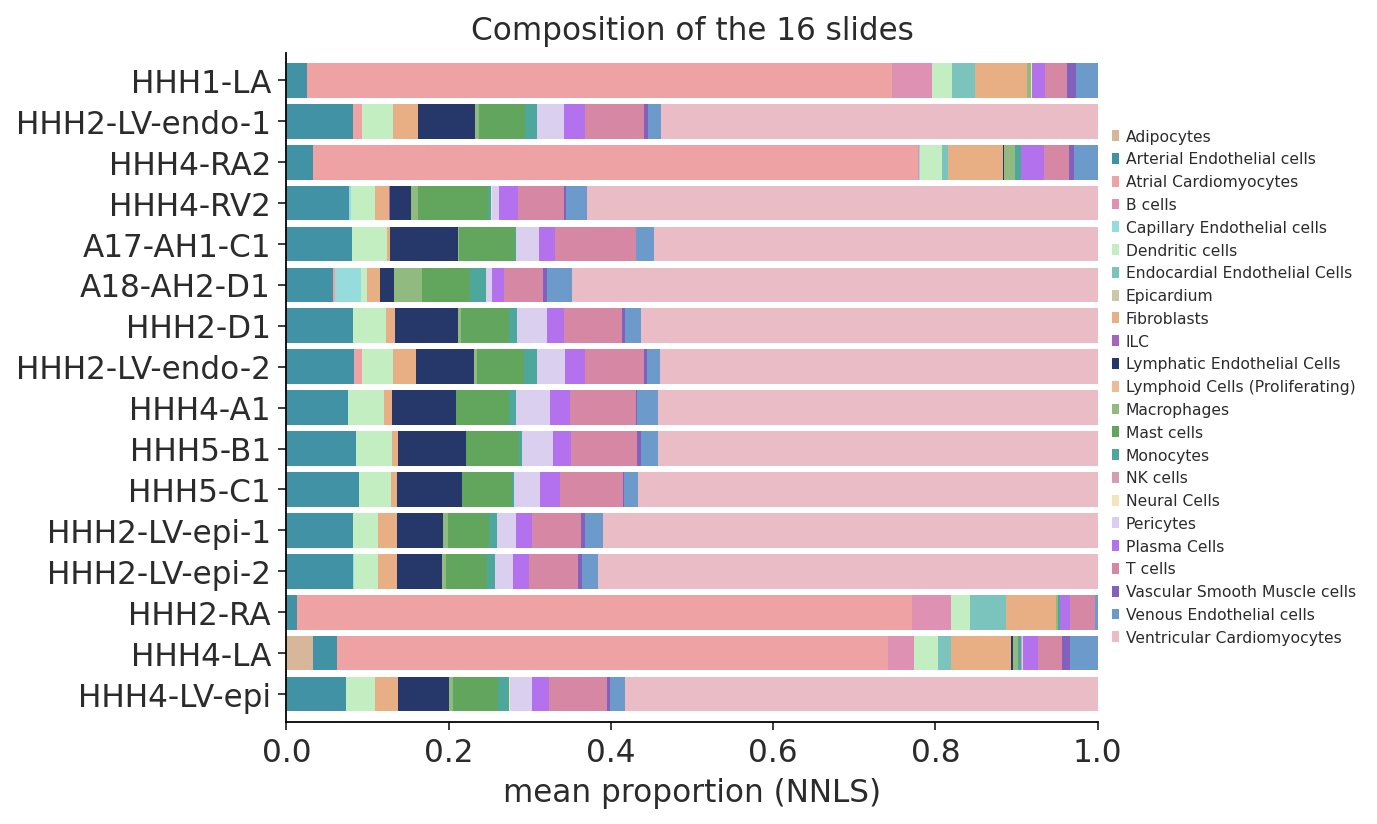

In [12]:
spots = {}
for name in all_slides:
    spots[name] = hhca.tl.visium_spots(f"{noseda}/{name}", qc["min_cells_per_gene"], qc["min_counts_per_spot"])
    hhca.tl.nnls_deconvolution(spots[name], signatures, n_top_genes, cardiac_markers)
mean_proportion = pd.DataFrame({name: spots[name].obsm["NNLS"].mean() for name in all_slides})
n_cohort_spots = sum(slide.n_obs for slide in spots.values())
print(f"{n_cohort_spots:,} spots on {len(spots)} slides")

colours = [style.CT[cell_type] for cell_type in cell_types]
ax = mean_proportion.T.plot.barh(stacked=True, color=colours, width=0.85, figsize=(6.5, 5.5))
ax.invert_yaxis()
ax.set(xlabel="mean proportion (NNLS)", xlim=(0, 1), title="Composition of the 16 slides")
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=7, ncol=1)
plt.show()

On our section NNLS attributes 54% of the mRNA to ventricular cardiomyocytes, and it also reports 8% arterial
endothelium, 7% T cells, 7% lymphatic endothelium and 6% mast cells, more than one expects in myocardium. Across
the 34,278 spots of the 16 slides the four atrial slides are dominated by atrial and the twelve ventricular slides
by ventricular cardiomyocytes.

## Spots of known composition from Visium HD

How good are these proportions? On a real Visium spot nobody knows the truth. On Visium HD we do: the same tissue
is measured at 2 µm, and every pixel carries a Level-3 type from the FICTURE decode. If we sum the transcripts of
a Visium HD section over squares of 55 µm, we get spots that look like standard Visium but whose composition we
can count.

We build such spots for one section, `VS_BO_HDZ150319_34_myo`. The inputs are the transcript table and the pixel
decode of the cell-typing pipeline, the gene list and the bounds of the section.

In [13]:
hd_section = slides_cfg["gtsim_hd"][0]
gtsim = cfg["gtsim"]
with open(inputs["factor_order_L3"]) as handle:
    factor_order = json.load(handle)
features = pd.read_csv(inputs["hd_features"].format(slide=hd_section), sep="\t")
hd_genes = features["gene"].astype(str).tolist()
bounds_table = pd.read_csv(inputs["hd_bounds"].format(slide=hd_section), sep="\t", header=None, index_col=0)
bounds = bounds_table[1]
print(f"{len(hd_genes):,} genes, {len(factor_order)} Level-3 types")
bounds.to_frame("µm").T

15,920 genes, 23 Level-3 types


,xmin,xmax,ymin,ymax
µm,1414.85,7815.77,4009.57,10150.71


`hhca.tl.simulate_spots` reads the decode and the transcripts in blocks. A tile becomes a spot when it has at
least 200 counts and 50 decoded pixels; the counts of the spot are the transcripts per gene, and its known
composition is the share of its decoded pixels per cell type (`obsm["truth"]`). This is an area fraction: a cell
type counts by the tissue area it covers.

In [14]:
sim = hhca.tl.simulate_spots(
    inputs["hd_transcripts"].format(slide=hd_section),
    inputs["hd_decode"].format(slide=hd_section),
    hd_genes,
    bounds,
    factor_order,
    tile_um=gtsim["tile_um"],
    min_counts=gtsim["min_counts"],
    min_pixels=gtsim["min_pixels"],
    min_cells=gtsim["min_cells"],
    chunksize=gtsim["chunk"],
)
grid = sim.uns["grid"]
print(
    f"{grid['n_transcripts']:,} transcript rows, {grid['n_decoded_pixels']:,} decoded pixels, {grid['n_tiles']:,} tiles"
)
sim

80,178,809 transcript rows, 6,930,447 decoded pixels, 13,104 tiles


AnnData object with n_obs × n_vars = 5964 × 15107
    obs: 'array_row', 'array_col', 'total_counts', 'n_bins'
    uns: 'grid'
    obsm: 'spatial', 'truth', 'truth_pixels'

The pipeline builds these spots for all four sections with `scripts/deconvolution/build_sim.py`. Counts and
decoded pixels (`n_bins`) per simulated spot:

In [15]:
sim.obs[["total_counts", "n_bins"]].describe().loc[["50%", "min", "max"]].round(0)

,total_counts,n_bins
50%,14802.0,1171.0
min,217.0,50.0
max,32604.0,2486.0


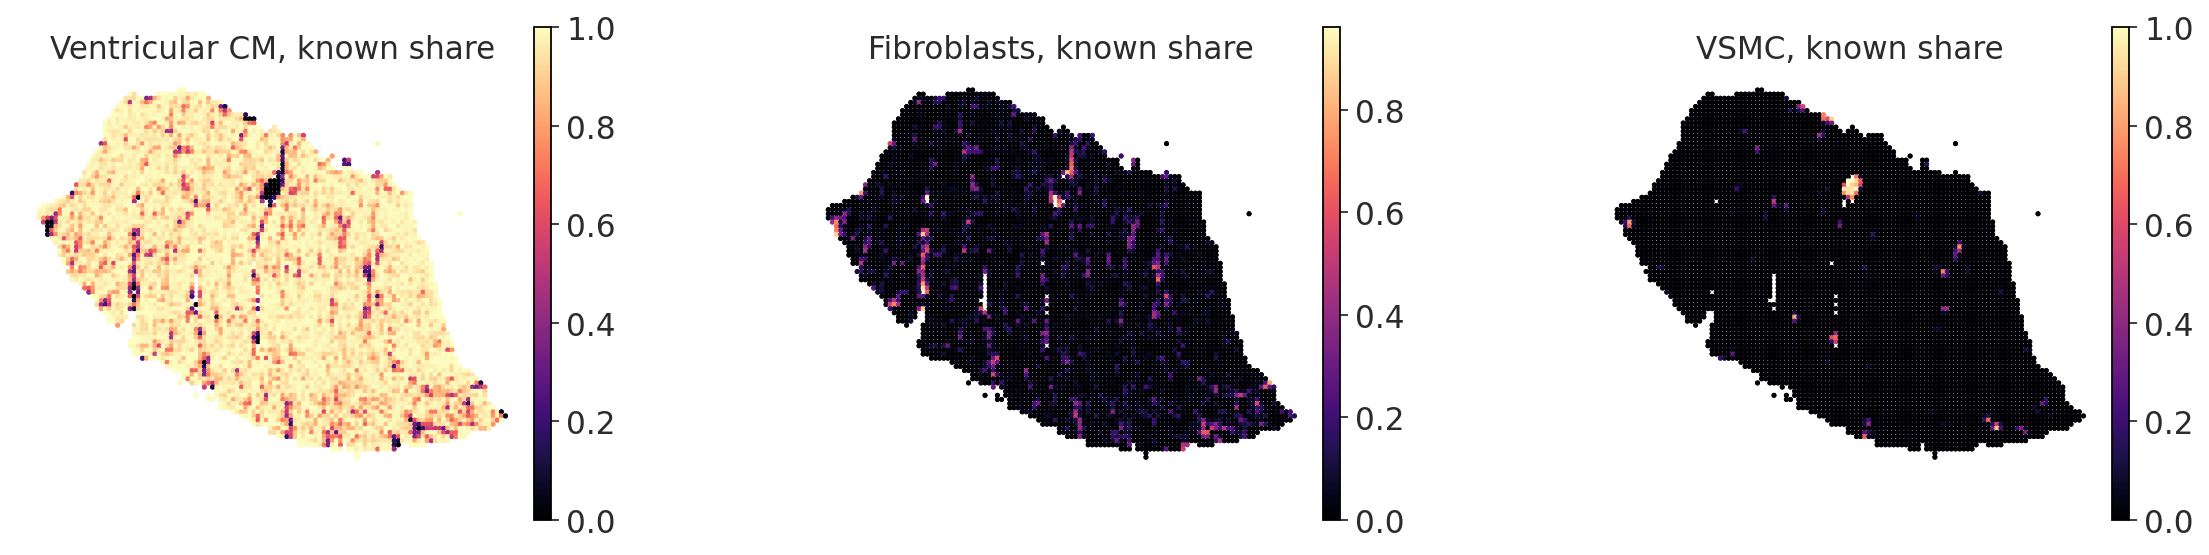

In [16]:
shown = ["Ventricular Cardiomyocytes", "Fibroblasts", "Vascular Smooth Muscle cells"]
titles = ["Ventricular CM, known share", "Fibroblasts, known share", "VSMC, known share"]
sim.obs[shown] = sim.obsm["truth"][shown]
sq.pl.spatial_scatter(
    sim, color=shown, shape=None, size=6, cmap=style.SEQUENTIAL, figsize=(4, 4), title=titles, wspace=0.4
)

The deconvolution methods are run on at most 5,000 spots per section. `hhca.tl.subsample_spots` draws them with
the seed of the configuration, as `scripts/deconvolution/prep_sim_inputs.py` does for every section.

In [17]:
rng = np.random.default_rng(gtsim["seed"])
sim = hhca.tl.subsample_spots(sim, gtsim["max_spots"], rng)
truth_mean = sim.obsm["truth"].mean().sort_values(ascending=False)
print(f"{sim.n_obs:,} spots")
truth_mean.head(6).round(4).to_frame("mean known share")

5,000 spots


,mean known share
Ventricular Cardiomyocytes,0.9114
Fibroblasts,0.0419
Pericytes,0.0131
Capillary Endothelial cells,0.0121
Vascular Smooth Muscle cells,0.0089
Macrophages,0.0057


Now we deconvolve the simulated spots with NNLS. Here the signatures come from the single-cell reference, as for
the other methods: `hhca.tl.reference_signatures` averages the nuclei of each type after scaling them to 10,000
counts.

In [18]:
reference_profiles = hhca.tl.reference_signatures(reference)
hhca.tl.nnls_deconvolution(sim, reference_profiles, n_top_genes, cardiac_markers)
n_fit_genes = len(sim.uns["NNLS"]["genes"])
print(f"NNLS on {sim.n_obs:,} spots with {n_fit_genes:,} genes")

NNLS on 5,000 spots with 2,011 genes


`hhca.tl.score_proportions` compares the estimate with the known composition. Over all spots and cell types it
returns the root mean squared error (RMSE) and the mean absolute error; per spot the Jensen–Shannon distance (JSD)
between the two compositions, averaged over spots; and per cell type the correlation across spots.

In [19]:
nnls_overall, nnls_per_type = hhca.tl.score_proportions(sim.obsm["truth"], sim.obsm["NNLS"])
nnls_scores = pd.Series(nnls_overall).drop("n_spots")
print(", ".join(f"{name} {value:.3f}" for name, value in nnls_scores.items()))
most_abundant = truth_mean.index[:6]
nnls_per_type.loc[most_abundant, ["truth_mean", "pred_mean", "rmse", "pearson"]].round(3)

rmse 0.145, mae 0.057, jsd 0.562, pearson 0.296, spearman 0.188


,truth_mean,pred_mean,rmse,pearson
Ventricular Cardiomyocytes,0.911,0.281,0.645,0.486
Fibroblasts,0.042,0.040,0.036,0.913
Pericytes,0.013,0.061,0.054,0.643
Capillary Endothelial cells,0.012,0.000,0.028,0.334
Vascular Smooth Muscle cells,0.009,0.044,0.041,0.947
Macrophages,0.006,0.010,0.022,0.816


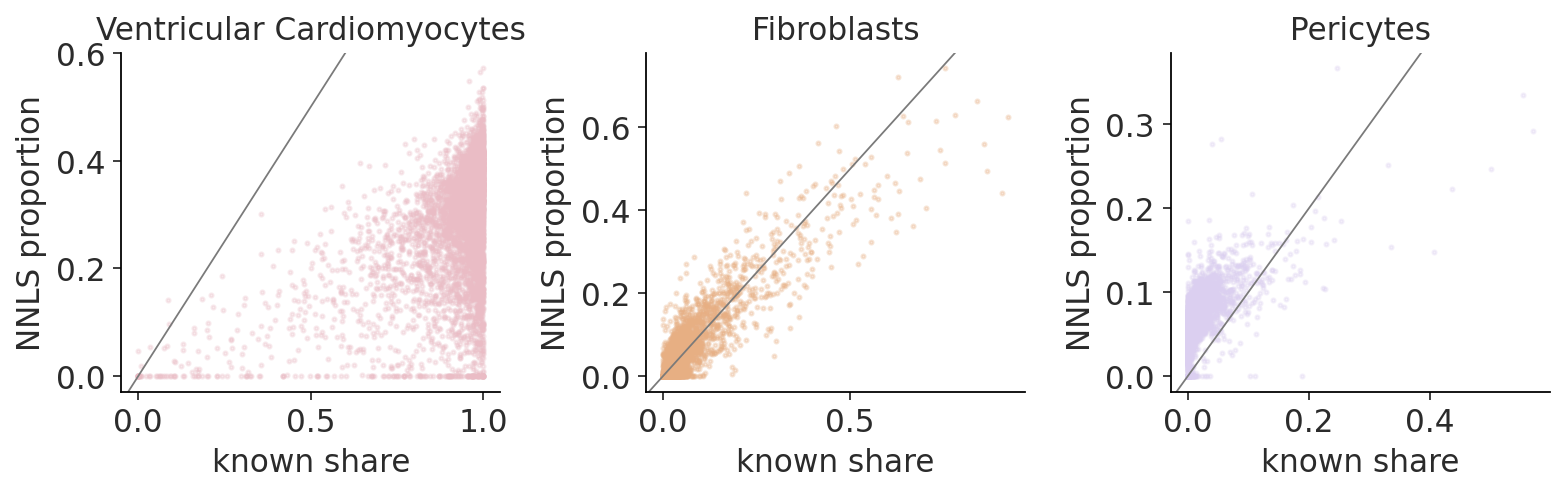

In [20]:
shown = ["Ventricular Cardiomyocytes", "Fibroblasts", "Pericytes"]
fig, axes = plt.subplots(1, 3, figsize=(10, 3.3))
for ax, cell_type in zip(axes, shown):
    known = sim.obsm["truth"][cell_type]
    estimated = sim.obsm["NNLS"][cell_type]
    ax.scatter(known, estimated, s=3, alpha=0.3, color=style.CT[cell_type])
    ax.axline((0, 0), slope=1, color=style.MUTED, lw=0.8)
    ax.set(xlabel="known share", ylabel="NNLS proportion", title=cell_type)
plt.tight_layout()
plt.show()

The section gives 5,964 simulated spots with a median of 14,802 counts and 1,171 decoded pixels; 5,000 of them are
used. Ventricular cardiomyocytes cover 91% of their area and fibroblasts 4%. NNLS reaches an RMSE of 0.145, a
Jensen–Shannon distance of 0.562 and a mean correlation of 0.296. It follows fibroblasts (r = 0.91) and smooth
muscle (r = 0.95) well from spot to spot, but it gives ventricular cardiomyocytes a mean proportion of 0.28 where
they cover 0.91 of the spot.

## Seven methods on the simulated spots

NNLS is a baseline. The six published methods model the counts more carefully, and need a GPU or R:

- **cell2location** estimates reference signatures with a negative-binomial regression and then the abundance of
  each type per spot in a Bayesian model
  (`sbatch workflow/hpc/deconvolution_gpu.sbatch c2l_train gtsim`, then `... c2l gtsim`).
- **stereoscope** fits negative-binomial parameters per gene and type on the reference and then the mixture per
  spot (`... stereo_train gtsim`, then `... stereo gtsim`).
- **spotiphy** selects marker genes per type and fits the proportions with a probabilistic model in pyro
  (`... spotiphy gtsim`).
- **UCASpatial** weights genes by how specific they are for a type and factorises the reference with NMF
  (`sbatch workflow/hpc/deconvolution_cpu.sbatch ucaspatial gtsim`).
- **RCTD** fits a Poisson mixture with a platform-effect correction, in R (`... RCTD gtsim`).
- **SPOTlight** seeds an NMF with marker genes and solves each spot by NNLS on the topics, in R
  (`... SPOTlight gtsim`).

Each job writes one table of spots × cell types. For the other three sections we load the simulated spots written
by `scripts/deconvolution/prep_sim_inputs.py`, and on all four we attach the table of each method as `obsm`; for
our section we keep the spots and the NNLS result from above.

In [21]:
methods = cfg["comparison"]["methods"]
simulated = {}
for name in slides_cfg["gtsim_hd"]:
    if name == hd_section:
        section_spots = sim
    else:
        section_spots = sc.read_h5ad(f"{results}/gtsim/data/{name}/slide.h5ad")
        truth_file = f"{results}/gtsim/data/{name}/truth_proportions.csv.gz"
        truth = hhca.tl.read_proportions(truth_file, cell_types, normalise=False)
        section_spots.obsm["truth"] = truth.reindex(section_spots.obs_names)
    for method in methods:
        if method in section_spots.obsm:  # NNLS of our section, computed above
            continue
        output_file = f"{results}/gtsim/outputs/hhca/{method}/{name}.csv.gz"
        proportions = hhca.tl.read_proportions(output_file, cell_types, normalise=False)
        section_spots.obsm[method] = proportions.reindex(section_spots.obs_names)
    simulated[name] = section_spots
simulated[hd_section]

AnnData object with n_obs × n_vars = 5000 × 15107
    obs: 'array_row', 'array_col', 'total_counts', 'n_bins', 'Ventricular Cardiomyocytes', 'Fibroblasts', 'Vascular Smooth Muscle cells'
    uns: 'grid', 'NNLS'
    obsm: 'spatial', 'truth', 'truth_pixels', 'NNLS', 'cell2location', 'stereoscope', 'spotiphy', 'ucaspatial', 'SPOTlight', 'RCTD'

`hhca.tl.score_methods` scores every method on every section, and `hhca.tl.leaderboard` averages the scores over
the sections and ranks the methods: `score` is the mean of the ranks by RMSE, JSD and Pearson r. In the pipeline,
`scripts/deconvolution/score_gt.py` writes these tables.

In [22]:
wall_position = slides_cfg["gtsim_region"]
overall, per_type = hhca.tl.score_methods(simulated, methods, wall_position)
board = hhca.tl.leaderboard(overall).reset_index(drop=True)
print(f"{len(overall)} method x section scores and {len(per_type)} cell-type scores")
board[["method", "rmse", "jsd", "pearson", "n_slides", "score"]].round(4)

28 method x section scores and 644 cell-type scores


,method,rmse,jsd,pearson,n_slides,score
0,spotiphy,0.0556,0.2647,0.4766,4,1.0000
1,RCTD,0.0827,0.3414,0.4289,4,2.0000
2,cell2location,0.1157,0.4412,0.3765,4,3.3333
3,ucaspatial,0.1335,0.5163,0.4209,4,4.3333
4,stereoscope,0.1374,0.5092,0.3146,4,5.3333
5,SPOTlight,0.1384,0.5146,0.3392,4,5.6667
6,NNLS,0.1350,0.5334,0.3033,4,6.3333


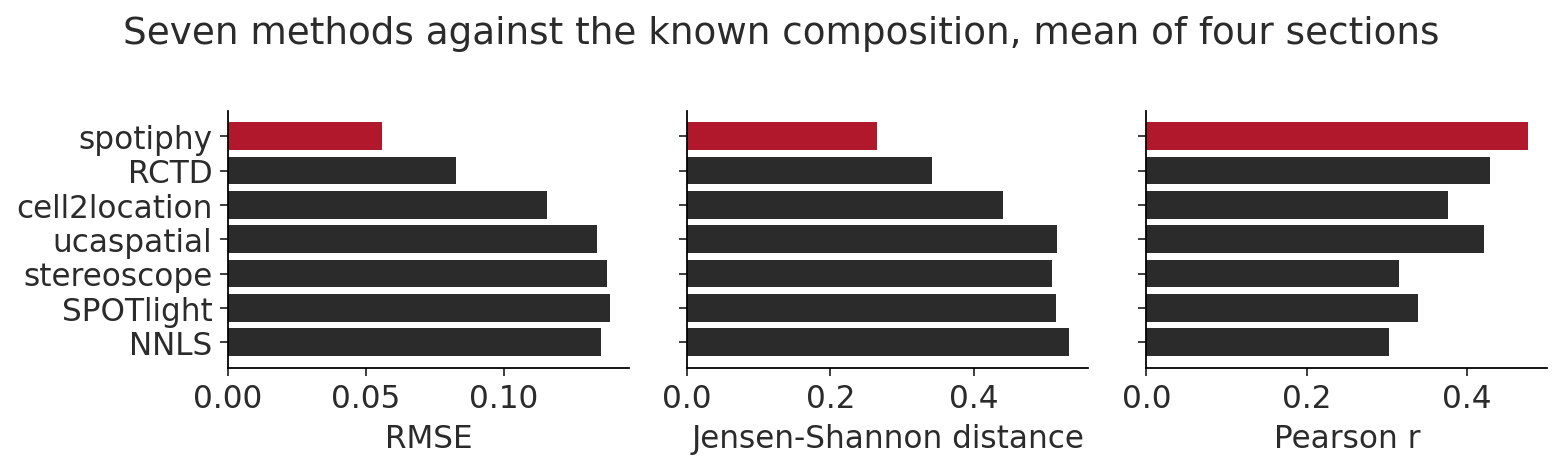

In [23]:
metric_labels = {"rmse": "RMSE", "jsd": "Jensen-Shannon distance", "pearson": "Pearson r"}
ranked = board.iloc[::-1]
bar_colours = [style.METHOD[method] for method in ranked["method"]]
fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
for ax, (metric, label) in zip(axes, metric_labels.items()):
    ax.barh(ranked["method"], ranked[metric], color=bar_colours)
    ax.set(xlabel=label)
fig.suptitle("Seven methods against the known composition, mean of four sections")
plt.tight_layout()
plt.show()

The ranking could hide differences between cell types: a method may be good for the abundant cardiomyocytes and
poor for rare immune cells. `hhca.tl.celltype_scores` averages RMSE and correlation per cell type and method.

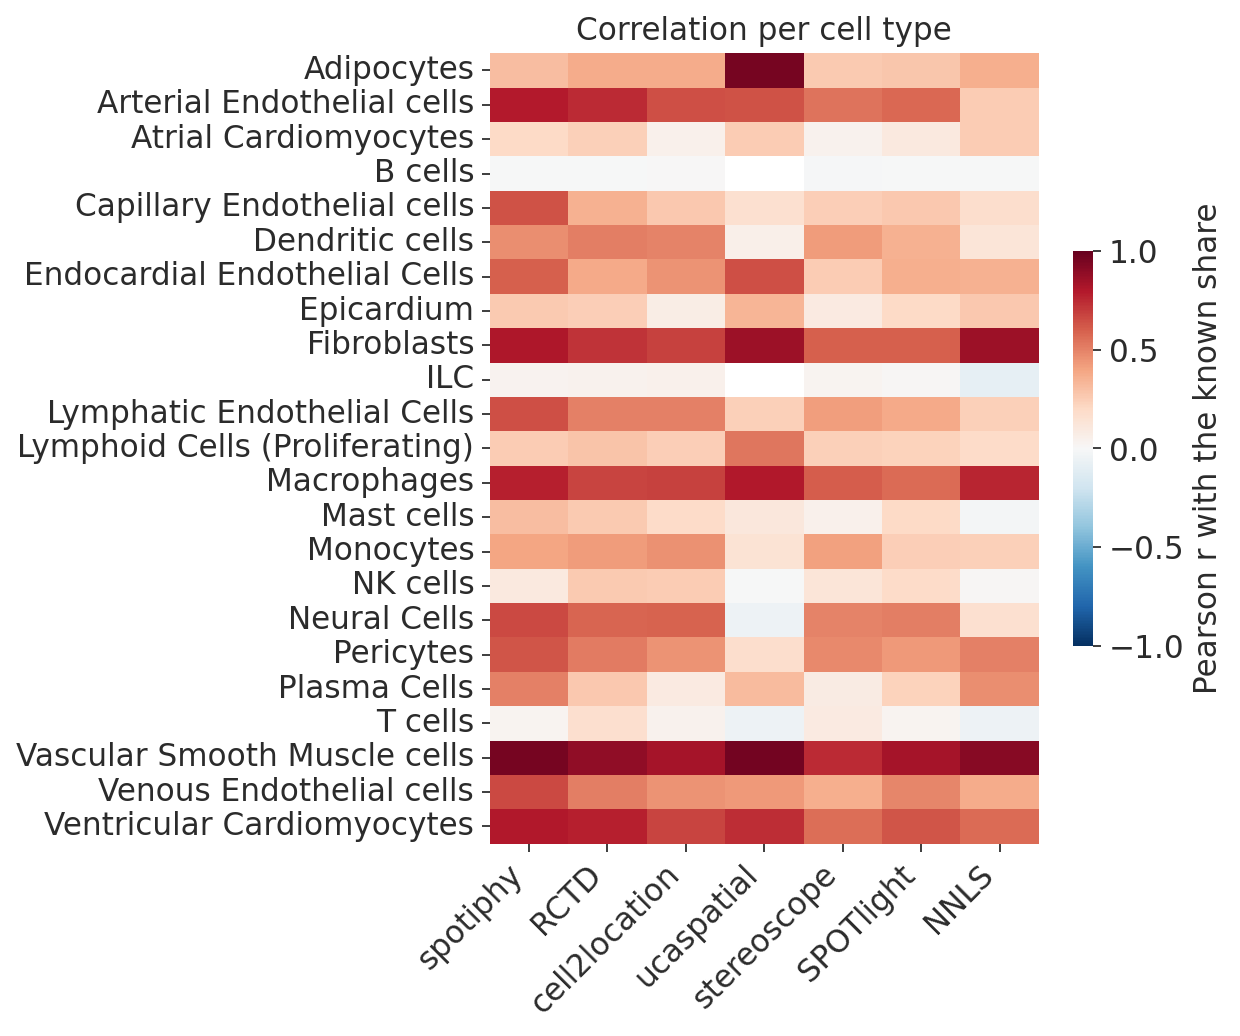

In [24]:
by_type = hhca.tl.celltype_scores(per_type, cell_types)
correlation = by_type["pearson"][board["method"]]
fig, ax = plt.subplots(figsize=(5.5, 6.5))
sns.heatmap(
    correlation,
    cmap=style.DIVERGING,
    center=0,
    vmin=-1,
    vmax=1,
    cbar_kws={"shrink": 0.5, "label": "Pearson r with the known share"},
    ax=ax,
)
ax.set(xlabel="", ylabel="", title="Correlation per cell type")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.show()

In [25]:
best = by_type["best"]
wins = pd.DataFrame(
    {
        "lowest RMSE": best["best_rmse_method"].value_counts(),
        "highest Pearson r": best["best_corr_method"].value_counts(),
    }
)
wins = wins.reindex(board["method"]).fillna(0).astype(int)
wins.rename_axis("cell types where the method is best")

,lowest RMSE,highest Pearson r
cell types where the method is best,,
spotiphy,8,9
RCTD,2,3
cell2location,0,3
ucaspatial,11,6
stereoscope,0,0
SPOTlight,0,0
NNLS,2,2


In [26]:
rmse = overall.pivot_table(index="method", columns="region", values="rmse")
by_region = rmse.loc[board["method"], ["epi", "myo", "endo"]]
by_region.round(4)

region,epi,myo,endo
method,,,
spotiphy,0.0535,0.0621,0.0449
RCTD,0.0826,0.0822,0.0838
cell2location,0.1176,0.1151,0.1151
ucaspatial,0.1408,0.1282,0.1370
stereoscope,0.1264,0.1460,0.1312
SPOTlight,0.1404,0.1373,0.1384
NNLS,0.1295,0.1381,0.1342


spotiphy is closest to the known composition on every measure (RMSE 0.056, Jensen–Shannon distance 0.265, mean
r = 0.477), followed by RCTD (0.083, 0.341, 0.429) and cell2location (0.116, 0.441, 0.376). NNLS ranks last of the
seven (0.135, 0.533, 0.303). spotiphy has the highest correlation for 9 of the 23 cell types and UCASpatial for 6,
and spotiphy has the lowest RMSE on the epicardial, mid-myocardial and endocardial sections alike (0.054, 0.062,
0.045).

## The methods on tissue sections

On the simulated spots the methods differ in accuracy. Do they also paint a different picture of a real section?
The six methods were run on the 11 slides with spot positions (the same jobs with `benchmark` in place of
`gtsim`). We attach their per-spot outputs to the slides, next to the NNLS result computed above.

In [27]:
benchmark_outputs = inputs["benchmark_outputs"]
sections = {name: spots[name] for name in benchmark}
for name, slide in sections.items():
    for method in methods:
        if method == "NNLS":  # computed above
            continue
        proportions = hhca.tl.read_proportions(f"{benchmark_outputs}/{method}/{name}.csv.gz", cell_types)
        slide.obsm[method] = proportions.reindex(slide.obs_names)
for method in methods:
    adata.obsm[method] = sections[section].obsm[method]
adata

AnnData object with n_obs × n_vars = 1963 × 15113
    obs: 'in_tissue', 'array_row', 'array_col', 'n_counts', 'dominant_L3', 'Ventricular Cardiomyocytes', 'Fibroblasts'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells'
    uns: 'spatial', 'NNLS', 'dominant_L3_colors'
    obsm: 'spatial', 'NNLS', 'cell2location', 'stereoscope', 'spotiphy', 'ucaspatial', 'SPOTlight', 'RCTD'

On our section we count, per method, the spots whose dominant type is a cardiomyocyte, and the mean cardiomyocyte
proportion.

In [28]:
downstream = cfg["downstream"]
cardiomyocytes = downstream["fig3c_cm"]
rows = []
for method in methods:
    proportions = adata.obsm[method]
    cm_dominant = proportions.idxmax(axis=1).isin(cardiomyocytes)
    cm_proportion = proportions[cardiomyocytes].sum(axis=1)
    rows.append({"CM-dominant spots (%)": 100 * cm_dominant.mean(), "mean CM proportion": cm_proportion.mean()})
cm_by_method = pd.DataFrame(rows, index=methods)
cm_by_method.loc[board["method"]].round(3)

,CM-dominant spots (%),mean CM proportion
spotiphy,98.879,0.791
RCTD,97.759,0.570
cell2location,91.136,0.543
ucaspatial,97.045,0.590
stereoscope,68.925,0.190
SPOTlight,89.862,0.393
NNLS,98.879,0.549


`hhca.pl.method_maps` draws ED6 g: the dominant type of every spot per method, and the spots of a zoom window as
pies of their proportions.

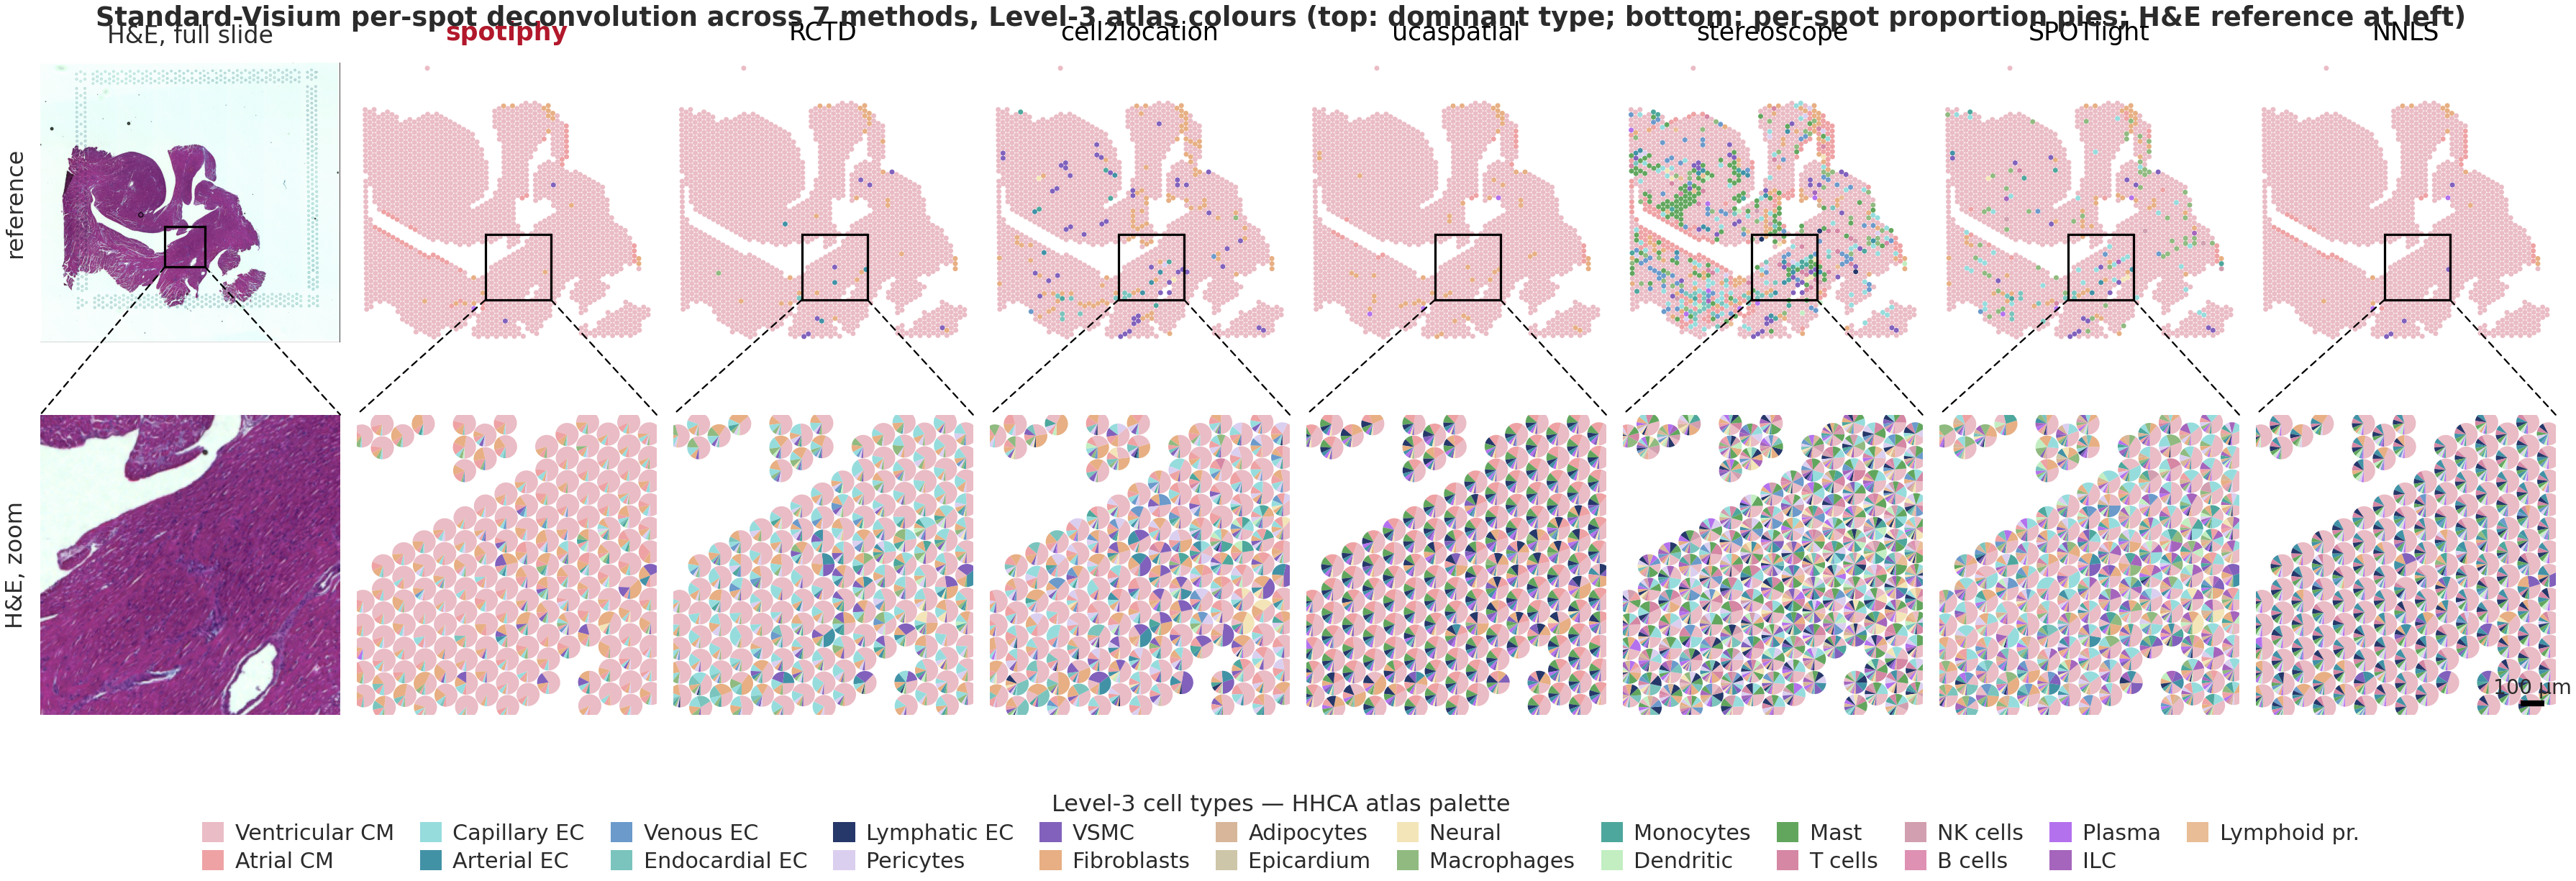

In [29]:
fig = hhca.pl.method_maps(adata, figures_cfg["ed6_g_fov"])

`hhca.pl.spot_pies` draws the Visium row of ED6 c, the spotiphy proportions in a window of the same section.

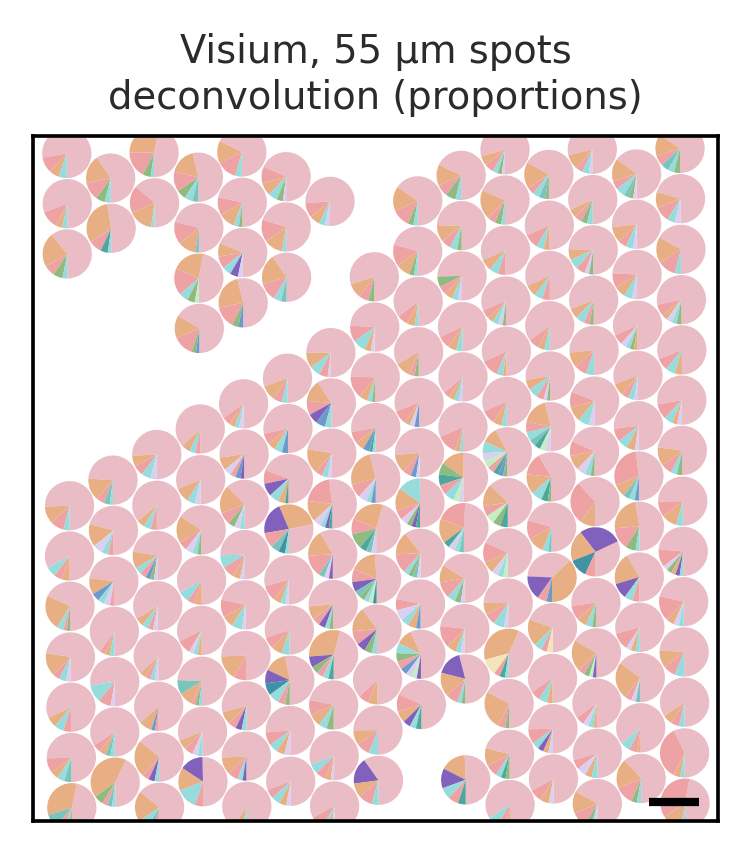

In [30]:
fig = hhca.pl.spot_pies(adata, "spotiphy", figures_cfg["ed6_c_fov"])

For the whole cohort we summarise the 23 types into 11 compartments. `hhca.tl.section_chambers` calls a slide
atrial or ventricular from its NNLS result, and `hhca.tl.compartment_composition` returns the mean proportion of
each compartment per method and slide.

In [31]:
comparison = cfg["comparison"]
compartments = comparison["compartments"]
atrial_cm, ventricular_cm = cardiomyocytes
chambers = hhca.tl.section_chambers(sections, atrial_cm, ventricular_cm, atrial_sections=comparison["atrial_slides"])
composition = hhca.tl.compartment_composition(sections, methods, compartments, chambers)
composition_mean = composition.groupby("method")[list(compartments)].mean()

chamber_of_slide = pd.Series(chambers)
atrial_slides = list(chamber_of_slide.index[chamber_of_slide == "atrial"])
print(f"{len(composition)} method x slide rows; atrial slides: {atrial_slides}")
shown_compartments = ["CM", "Fibroblast", "Endothelial", "Pericyte", "Myeloid", "Lymphoid", "Mast"]
composition_mean.loc[board["method"], shown_compartments].round(3)

77 method x slide rows; atrial slides: ['HHH1-LA', 'HHH4-RA2']


,CM,Fibroblast,Endothelial,Pericyte,Myeloid,Lymphoid,Mast
method,,,,,,,
spotiphy,0.804,0.086,0.051,0.012,0.026,0.007,0.001
RCTD,0.550,0.085,0.183,0.043,0.068,0.018,0.003
cell2location,0.570,0.083,0.137,0.045,0.040,0.044,0.009
ucaspatial,0.555,0.028,0.184,0.026,0.014,0.062,0.081
stereoscope,0.194,0.032,0.189,0.037,0.074,0.302,0.068
SPOTlight,0.370,0.081,0.191,0.032,0.116,0.100,0.008
NNLS,0.600,0.024,0.153,0.024,0.049,0.092,0.053


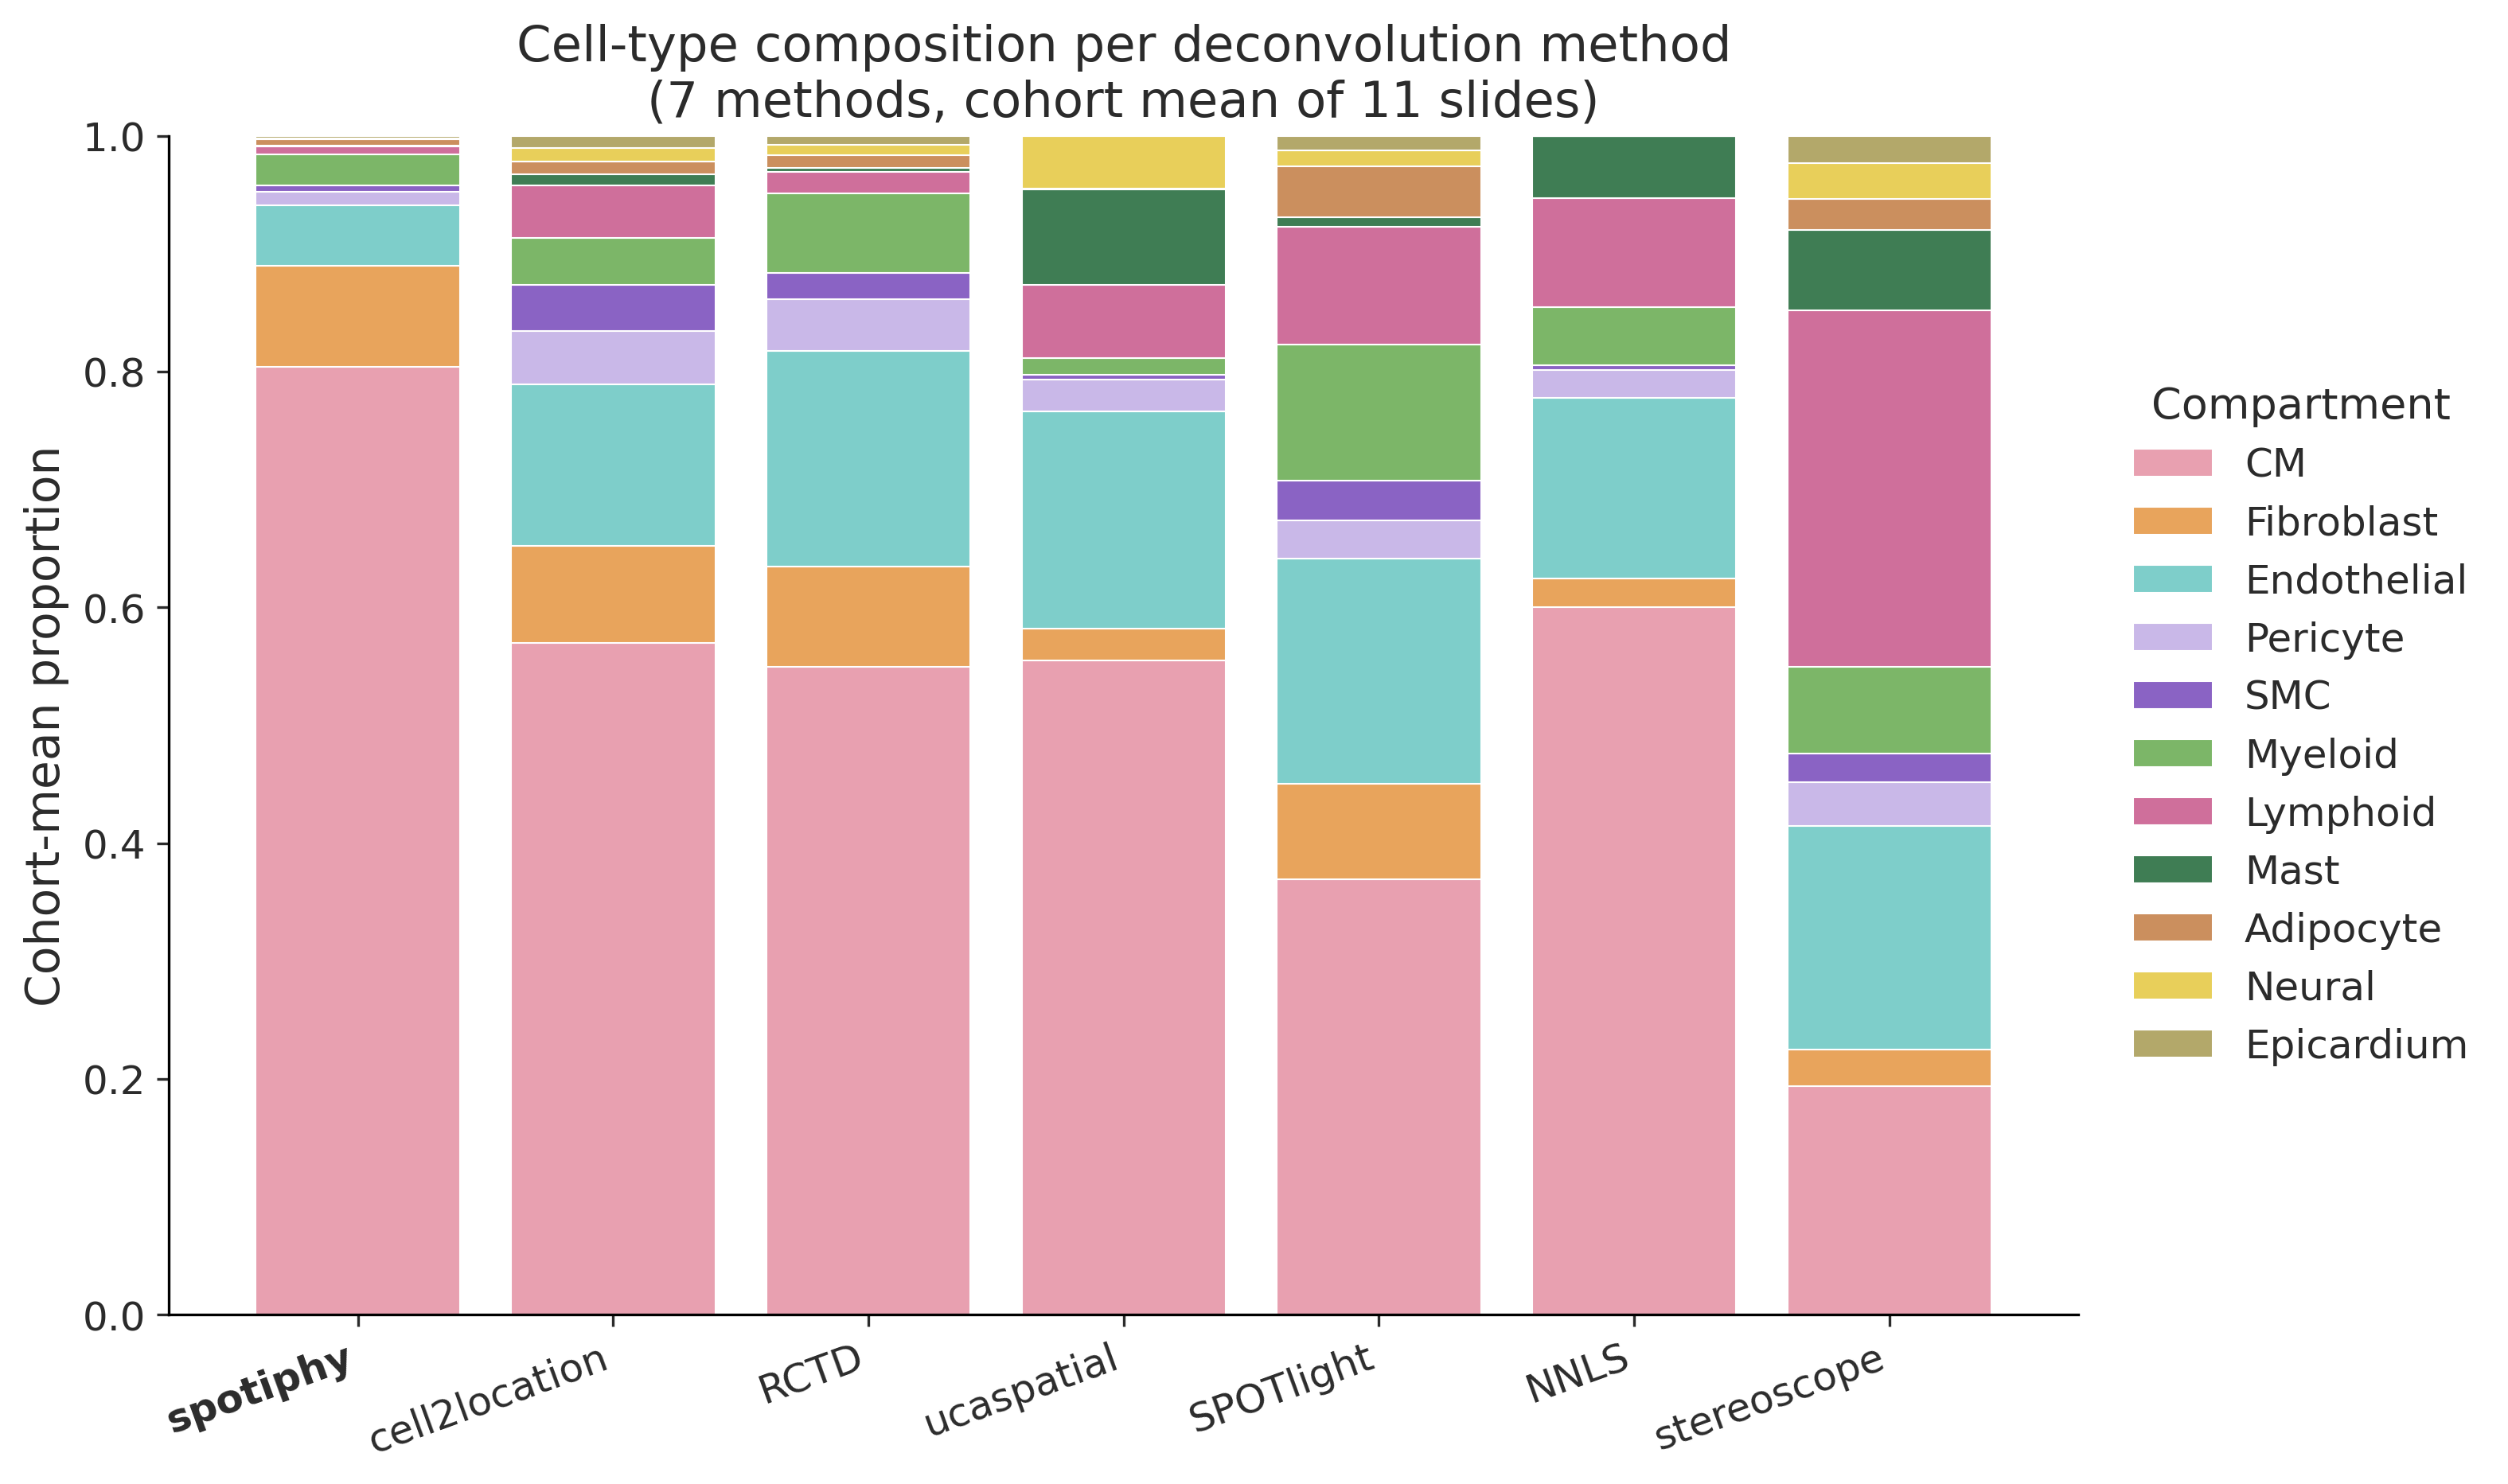

In [32]:
fig = hhca.pl.method_composition(composition_mean)

How similar are the methods spot by spot? `hhca.tl.method_concordance` correlates the proportions of every pair
of methods across the spots of a slide, per cell type, and averages over cell types and slides.

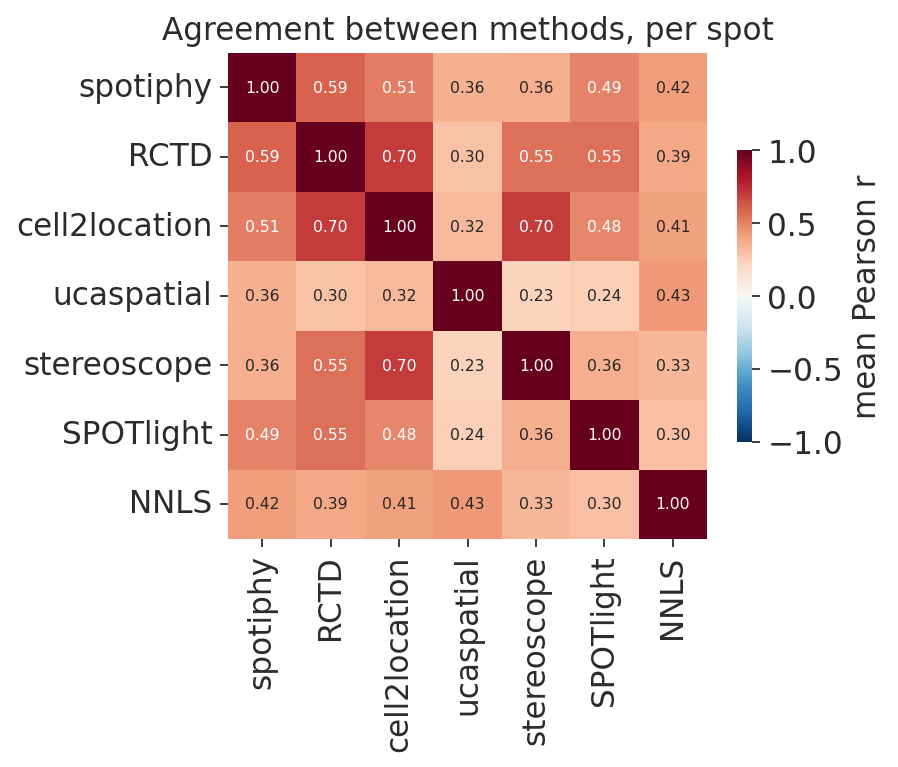

In [33]:
concordance = hhca.tl.method_concordance(sections, methods)
order = list(board["method"])
pearson = concordance["pearson"].loc[order, order]
fig, ax = plt.subplots(figsize=(4.8, 4))
sns.heatmap(
    pearson,
    cmap=style.DIVERGING,
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    cbar_kws={"shrink": 0.6, "label": "mean Pearson r"},
    ax=ax,
)
ax.set(title="Agreement between methods, per spot")
plt.show()

In [34]:
floor_cfg = comparison["floor"]
floor, n_floor = hhca.tl.background_floor(
    sections,
    methods,
    chambers,
    cell_types=floor_cfg["cell_types"],
    min_ventricular=floor_cfg["min_ventricular"],
    min_ratio=floor_cfg["min_ratio"],
    max_cv=floor_cfg["max_cv"],
)
ventricular_means = floor.pivot(index="cell_type", columns="method", values="ventricular_mean")
ventricular_means[order].round(3)

method,spotiphy,RCTD,cell2location,ucaspatial,stereoscope,SPOTlight,NNLS
cell_type,,,,,,,
Dendritic cells,0.007,0.006,0.009,0.009,0.025,0.023,0.036
Lymphatic Endothelial Cells,0.002,0.010,0.016,0.080,0.040,0.010,0.066
Mast cells,0.001,0.003,0.009,0.087,0.074,0.008,0.064
T cells,0.001,0.002,0.006,0.003,0.068,0.008,0.074


The methods disagree most about the cardiomyocytes. On our section between 69% (stereoscope) and 99% (spotiphy,
NNLS) of the spots are cardiomyocyte-dominant, and over the 11 slides the mean cardiomyocyte proportion ranges from
0.19 (stereoscope) to 0.80 (spotiphy). stereoscope gives 30% of the tissue to lymphoid cells. On ventricular slides
NNLS reports a constant 7% T cells, 7% lymphatic endothelium and 6% mast cells and UCASpatial 9% mast cells, where
spotiphy stays below 1% for each of these types. Spot by spot, cell2location agrees best with RCTD and stereoscope
(r = 0.70), and spotiphy best with RCTD (r = 0.59). Together with the simulated spots this makes spotiphy the
method whose proportions we show in ED6 c.

## Chamber markers in cardiomyocyte-dominant spots

The atlas gives a list of genes that separate atrial from ventricular cardiomyocytes. Do they separate the
chambers on Visium? Averaging a gene over all spots of a slide would mix two things: how cardiomyocytes differ
between chambers, and how much myocardium each section holds. We therefore keep only the spots whose dominant
cell type is a cardiomyocyte.

`hhca.tl.chamber_gene_panel` returns the genes of the panel with their direction in the atlas.

In [35]:
extra_gene = downstream["fig3c_extra_gene"]
gene_table = pd.read_csv("resources/deconvolution/concordance_per_gene.csv")
direction = hhca.tl.chamber_gene_panel(gene_table, extra=[extra_gene])
panel_genes = list(direction.index)
direction.value_counts().to_frame("genes")

,genes
snuc_dir,
atria,12
ventricle,5


On the Noseda slides the dominant type comes from our NNLS result. `hhca.tl.cardiomyocyte_dominant` marks the
spots in `obs["cm_dominant"]`; on our section:

1,941 of 1,963 spots are cardiomyocyte-dominant


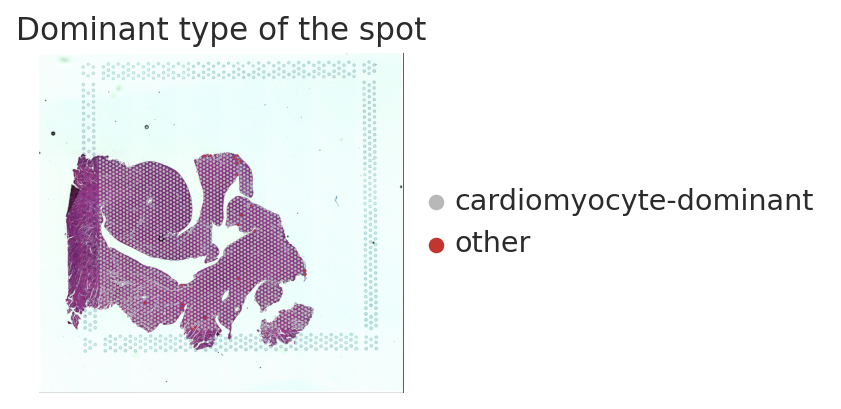

In [36]:
hhca.tl.cardiomyocyte_dominant(adata, cardiomyocytes, proportions=adata.obsm["NNLS"])
adata.obs["spot"] = pd.Categorical(np.where(adata.obs["cm_dominant"], "cardiomyocyte-dominant", "other"))
style.set_colors(adata, "spot", style.CM_DOMINANT)
n_cm_dominant = adata.obs["cm_dominant"].sum()
print(f"{n_cm_dominant:,} of {adata.n_obs:,} spots are cardiomyocyte-dominant")
sq.pl.spatial_scatter(adata, color="spot", library_id=section, figsize=(5, 5), title="Dominant type of the spot")

The second cohort, Kanemaru et al. 2023, comes with the authors' own cell2location result of 72 fine cell
states. `hhca.tl.lineage_proportions` sums them to coarse lineages; only the atrial and ventricular cardiomyocyte
states count as cardiomyocytes. We load the four chambers and keep them for the next section.

In [37]:
chamber_regions = slides_cfg["kanemaru_regions"]
kanemaru_cm = downstream["fig3c_cm_kanemaru"]
kanemaru = {}
lineages = {}
for region in chamber_regions:
    slide = sc.read_h5ad(f"{kanemaru_dir}/visium-OCT_{region}_lognormalised.h5ad")
    slide.var_names_make_unique()
    lineages[region] = hhca.tl.lineage_proportions(slide.obsm["prop"])
    hhca.tl.cardiomyocyte_dominant(slide, kanemaru_cm, proportions=lineages[region])
    kanemaru[region] = slide

last_region = chamber_regions[-1]
lineage_mean = lineages[last_region].mean().sort_values(ascending=False)
lineage_mean.head(6).round(3).to_frame(f"mean proportion, {last_region}")

,"mean proportion, RV"
Ventricular-CM,0.511
SMC,0.109
Endothelial,0.097
Fibroblast,0.073
Mesothelial,0.058
T/NK,0.057


`hhca.tl.chamber_sums` sums the log-normalised expression of the panel genes over all spots and over the
cardiomyocyte-dominant spots of a slide. We collect the sums of the four Kanemaru objects and of the ten Noseda
slides with a chamber region.

In [38]:
sum_tables = []
for region in chamber_regions:
    table = hhca.tl.chamber_sums(kanemaru[region], panel_genes)
    table["cohort"] = "kanemaru"
    table["region"] = region
    table["slide"] = f"visium-OCT_{region}"
    sum_tables.append(table)
for name, region in slides_cfg["fig3c_region"].items():
    slide = spots[name].copy()
    hhca.tl.cardiomyocyte_dominant(slide, cardiomyocytes, proportions=slide.obsm["NNLS"])
    sc.pp.normalize_total(slide, target_sum=1e4)
    sc.pp.log1p(slide)
    table = hhca.tl.chamber_sums(slide, panel_genes)
    table["cohort"] = "noseda"
    table["region"] = region
    table["slide"] = name
    sum_tables.append(table)
sums = pd.concat(sum_tables, ignore_index=True)

cohorts = {"kanemaru": "kanemaru", "noseda": "noseda"}
spot_counts = hhca.tl.region_spot_counts(sums, chamber_regions, cohorts)
spot_counts = spot_counts.set_index("region")
spot_counts[["kanemaru_total", "kanemaru_cm", "noseda_total", "noseda_cm", "combined_frac"]].round(3)

,kanemaru_total,kanemaru_cm,noseda_total,noseda_cm,combined_frac
region,,,,,
LA,5822,5070,4613,4222,0.890
RA,7027,5963,2435,2373,0.881
LV,9626,9222,10561,10409,0.972
RV,5039,4752,3555,3525,0.963


`hhca.tl.region_means` pools the sums of all slides of a region into the mean expression per gene, and
`hhca.tl.region_zscores` z-scores every gene across the four regions.

In [39]:
cm_means = hhca.tl.region_means(sums, chamber_regions, "cm")
cm_zscores = hhca.tl.region_zscores(cm_means)
atria_mean = cm_zscores[["LA", "RA"]].mean(axis=1)
ventricles_mean = cm_zscores[["LV", "RV"]].mean(axis=1)
higher_on_visium = (atria_mean > ventricles_mean).rename("higher in the atria on Visium")
pd.crosstab(direction.rename("direction in the atlas"), higher_on_visium)

higher in the atria on Visium,False,True
direction in the atlas,,
atria,0,12
ventricle,5,0


`hhca.pl.chamber_markers` draws Fig 3 c.

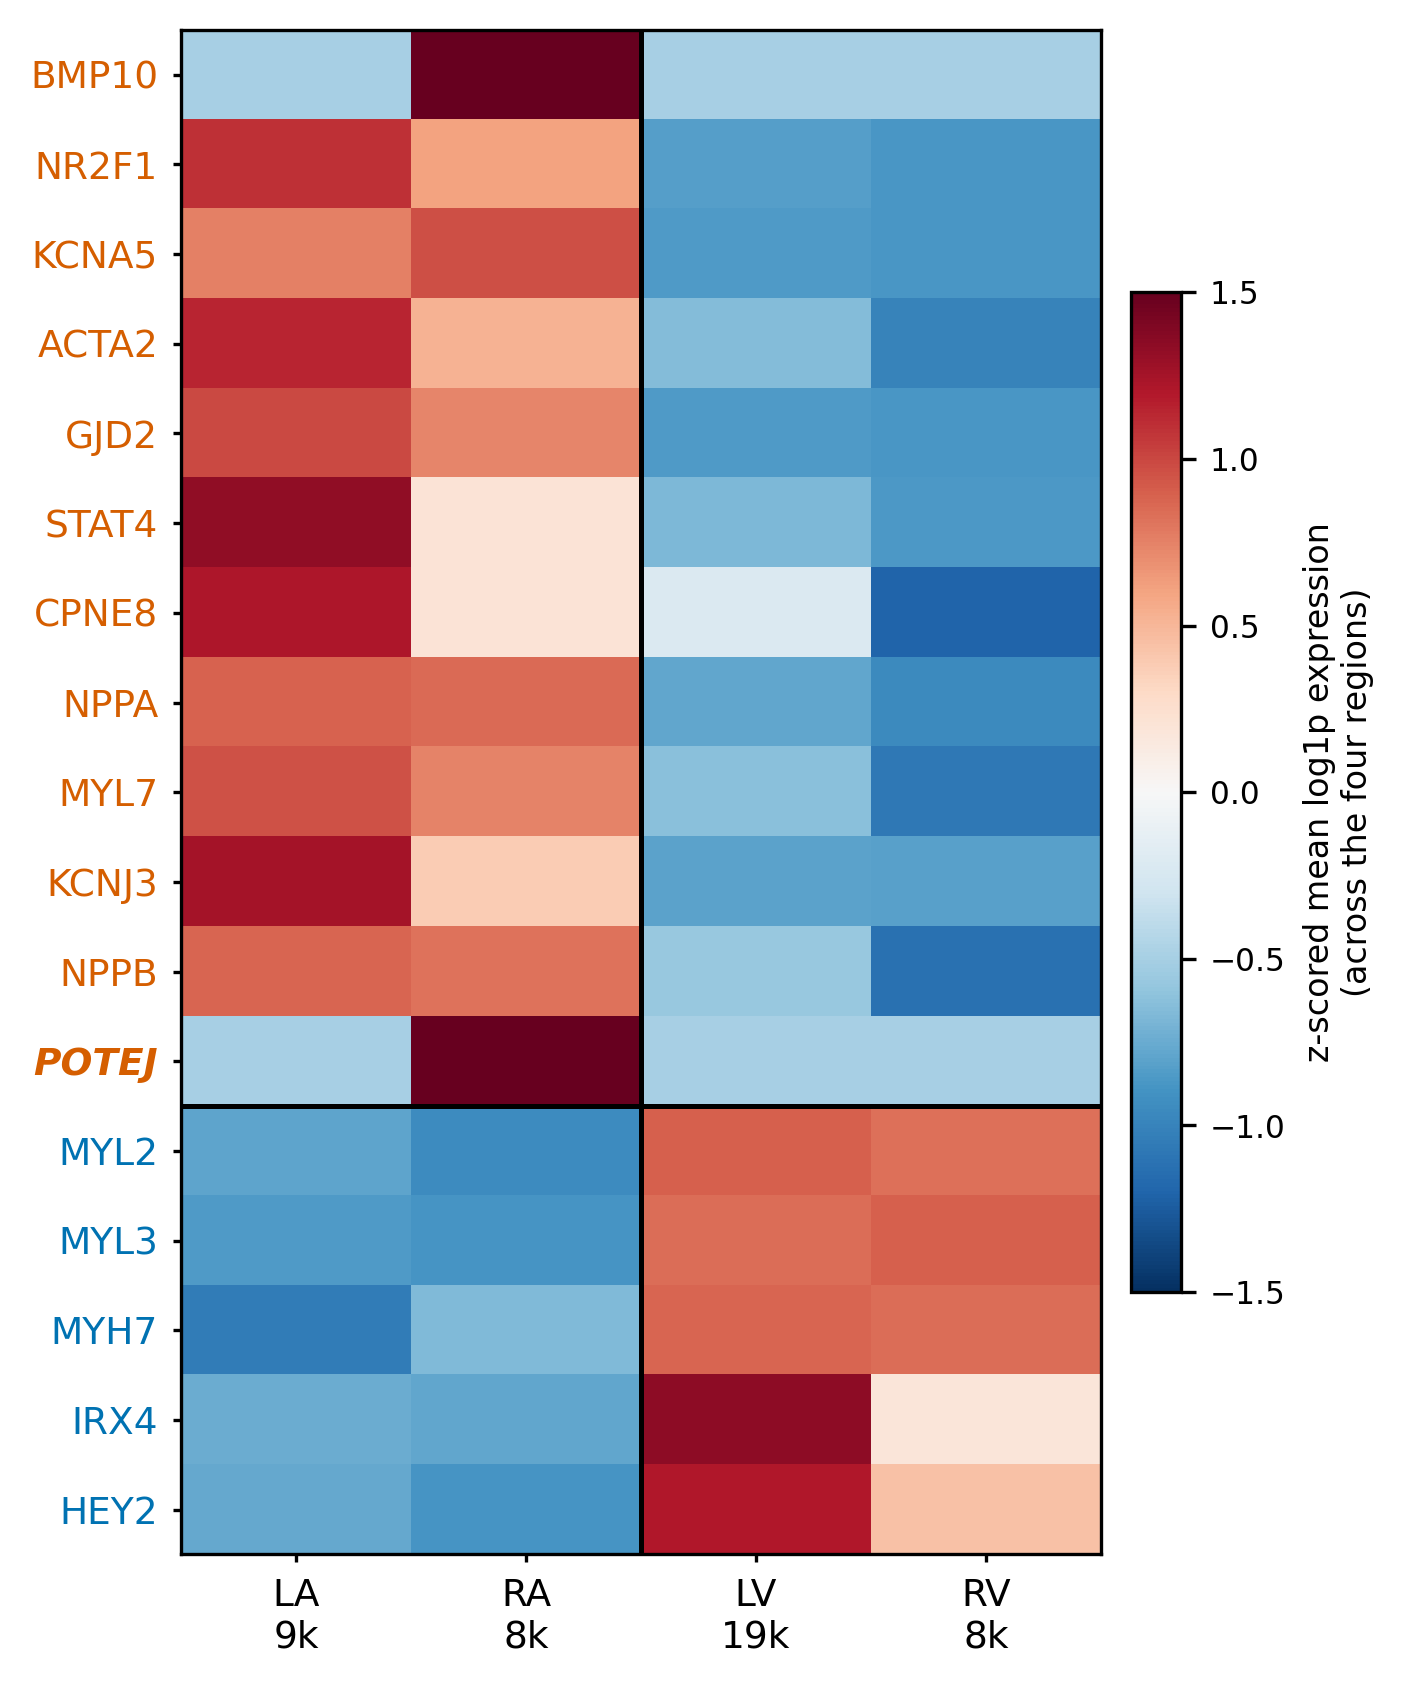

In [40]:
cm_spots = spot_counts["combined_cm"].to_dict()
fig = hhca.pl.chamber_markers(cm_zscores, direction, cm_spots, highlight=[extra_gene])

Most spots are cardiomyocyte-dominant: 1,941 of the 1,963 spots of our section, and 89% (LA), 88% (RA), 97% (LV)
and 96% (RV) of the spots of the two cohorts, 45,536 spots in all. In these spots all 12 atrial genes of the atlas
are higher in the atria and all 5 ventricular genes higher in the ventricles.

## The atrial-pericyte signature in pericyte-rich spots

In the atlas, pericytes of the atria differ from those of the ventricles in 30 genes. A Visium spot never contains
pericytes alone, but the deconvolution tells us which spots contain many. If the signature is real, pericyte-rich
spots of the atria should carry it more than pericyte-rich spots of the ventricles.

We take the signature genes from the four Kanemaru objects and join them into one `AnnData`, with the chamber, the
region (atria or ventricle), the donor and the summed abundance of the four pericyte states of the authors'
cell2location result. We use the total and not the atrial pericyte state alone: selecting spots by the atrial
state and then scoring an atrial signature would be circular.

In [41]:
with open("resources/deconvolution/atrial_pericyte_signature.json") as handle:
    signature = pd.Index(json.load(handle)["atrial_pericyte_markers"])
region_of_chamber = downstream["ed8_regions"]
pericyte_states = downstream["ed8_pericyte_kanemaru"]
by_chamber = []
for chamber, region in region_of_chamber.items():
    slide = kanemaru[chamber]
    measured = signature[signature.isin(slide.var_names)]
    part = slide[:, measured].copy()
    spot_obs = pd.DataFrame(index=part.obs_names)
    spot_obs["chamber"] = chamber
    spot_obs["region"] = region
    spot_obs["donor"] = part.obs["donor"].astype(str)
    spot_obs["peri"] = part.obs[pericyte_states].sum(axis=1)
    spot_obs["peri_atrial"] = part.obs["PC2_atria"]
    part.obs = spot_obs
    by_chamber.append(part)
pericytes = ad.concat(by_chamber)
missing = sorted(set(signature) - set(pericytes.var_names))
print(f"{len(signature)} signature genes, {pericytes.n_vars} measured; missing: {missing}")
pericytes

30 signature genes, 29 measured; missing: ['CCN4']


AnnData object with n_obs × n_vars = 27514 × 29
    obs: 'chamber', 'region', 'donor', 'peri', 'peri_atrial'
    obsm: 'MT', 'means_cell_abundance_w_sf', 'prop', 'q05_cell_abundance_w_sf', 'q95_cell_abundance_w_sf', 'spatial', 'stds_cell_abundance_w_sf'

`hhca.tl.score_signature` z-scores every gene across all spots, so that no highly expressed gene dominates, and
averages the z-scores per spot. `hhca.tl.signature_by_chamber` gives the mean z-score of each gene per chamber.

In [42]:
hhca.tl.score_signature(pericytes)
chamber_means = hhca.tl.signature_by_chamber(pericytes, list(region_of_chamber), sort_by=["LA", "RA"])
higher_in_atria = chamber_means[["LA", "RA"]].mean(axis=1) > chamber_means[["LV", "RV"]].mean(axis=1)
n_higher = higher_in_atria.sum()
not_higher = list(chamber_means.index[~higher_in_atria])
print(f"{n_higher} of {len(chamber_means)} genes are higher in the atria; not higher: {not_higher}")

27 of 29 genes are higher in the atria; not higher: ['DACH1', 'NLGN1']


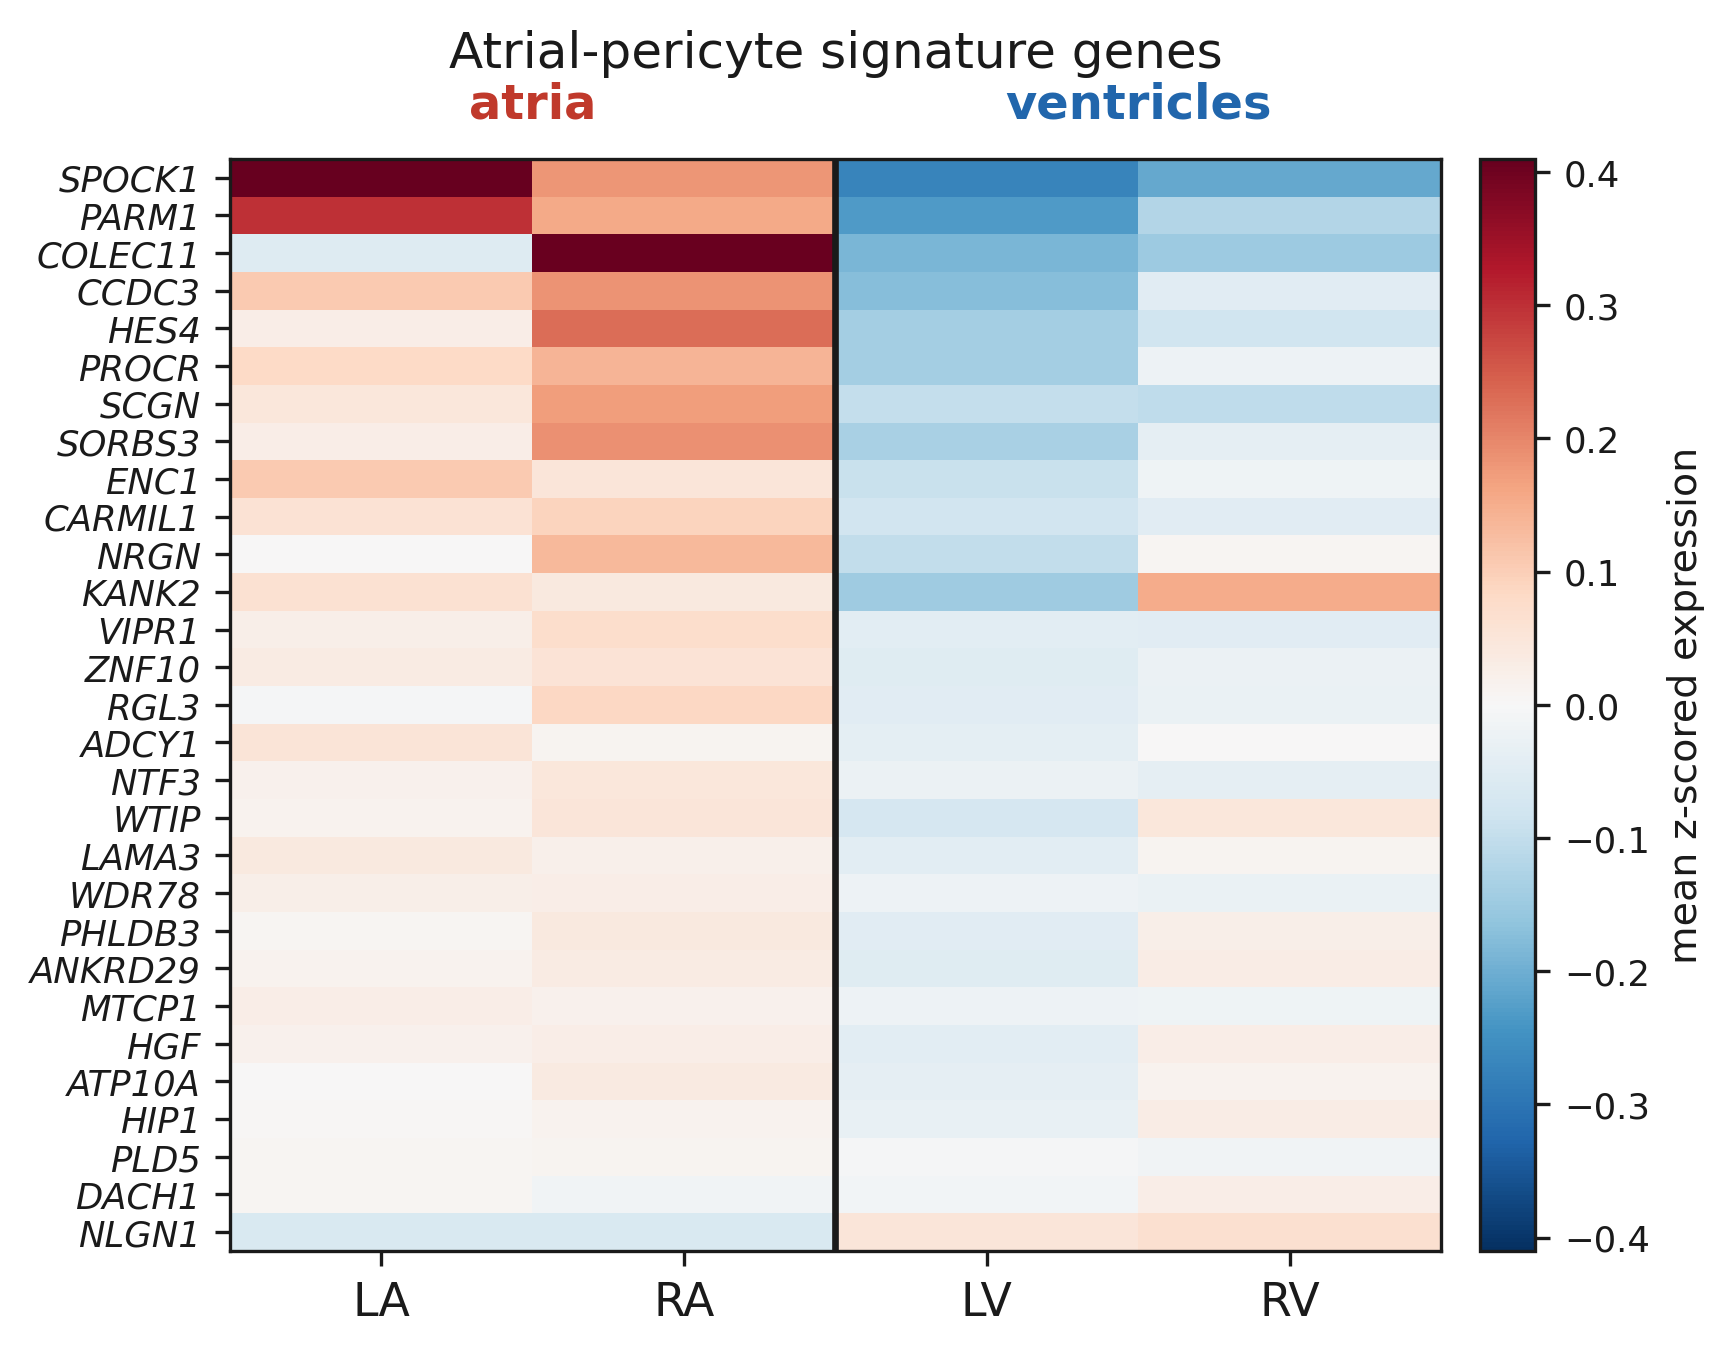

In [43]:
fig = hhca.pl.pericyte_signature(chamber_means, show=["genes"])

Higher expression in the atria alone does not show that pericytes are the source. `hhca.tl.abundance_groups`
splits the spots of each region into tertiles of pericyte abundance: the top third is pericyte-high, the bottom
third pericyte-low.

In [44]:
abundance_labels = ["pericyte-low", "pericyte-high"]
hhca.tl.abundance_groups(
    pericytes.obs, "peri", "region", downstream["ed8_tertile"], abundance_labels, key_added="peri_grp"
)
pd.crosstab(pericytes.obs["region"], pericytes.obs["peri_grp"])

peri_grp,pericyte-high,pericyte-low
region,,
atria,4283,4283
ventricle,4889,4888


`hhca.tl.compare_scores` compares the scores of two groups of spots with a two-sided Mann–Whitney U test: within
the atria, pericyte-high against pericyte-low spots; and among pericyte-high spots, atria against ventricles.

In [45]:
pericyte_spots = pericytes.obs
atria = pericyte_spots[pericyte_spots["region"] == "atria"]
pericyte_high = pericyte_spots[pericyte_spots["peri_grp"] == "pericyte-high"]
atria_low_scores = atria.loc[atria["peri_grp"] == "pericyte-low", "score"].values
atria_high_scores = atria.loc[atria["peri_grp"] == "pericyte-high", "score"].values
high_ventricle_scores = pericyte_high.loc[pericyte_high["region"] == "ventricle", "score"].values
high_atria_scores = pericyte_high.loc[pericyte_high["region"] == "atria", "score"].values
tests = pd.DataFrame(
    {
        "atria: pericyte-high against pericyte-low": hhca.tl.compare_scores(atria_low_scores, atria_high_scores),
        "pericyte-high: atria against ventricles": hhca.tl.compare_scores(high_ventricle_scores, high_atria_scores),
    }
).T
tests[["n_group", "n_reference", "median_group", "median_reference", "delta_median", "mwu_p"]]

,n_group,n_reference,median_group,median_reference,delta_median,mwu_p
atria: pericyte-high against pericyte-low,4283.0,4283.0,0.070147,-0.031548,0.101694,2.369132e-120
pericyte-high: atria against ventricles,4283.0,4889.0,0.070147,-0.077964,0.148111,2.802619e-265


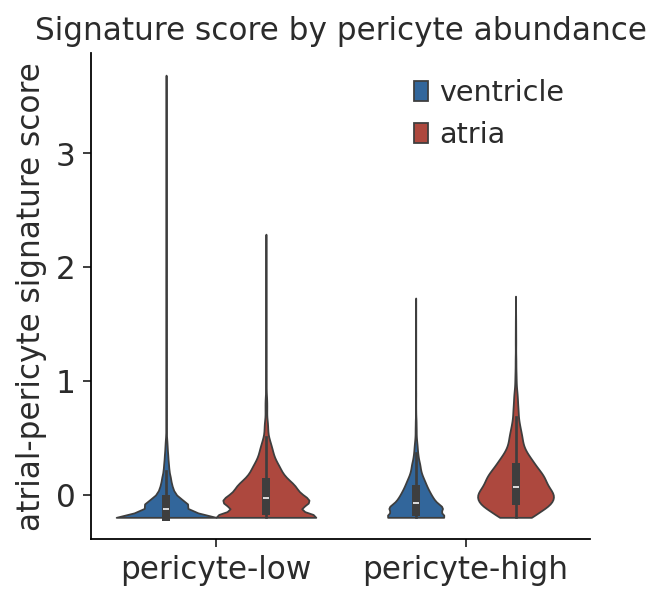

In [46]:
labelled = pericyte_spots.dropna(subset=["peri_grp"])
ax = sns.violinplot(
    labelled,
    x="peri_grp",
    y="score",
    hue="region",
    order=abundance_labels,
    hue_order=["ventricle", "atria"],
    palette=style.CHAMBER_REGION,
    linewidth=0.8,
    cut=0,
)
ax.set(xlabel="", ylabel="atrial-pericyte signature score", title="Signature score by pericyte abundance")
ax.legend(title="")
plt.show()

Spots of one donor are not independent. `hhca.tl.paired_donor_test` therefore repeats the comparison with the
donor as the unit: the mean score of the pericyte-high spots per donor and region.

In [47]:
donor_test = hhca.tl.paired_donor_test(pericyte_high)
print(f"{donor_test['n_donors']} donors with both regions, Wilcoxon p = {donor_test['wilcoxon_p']:.2f}")
pd.DataFrame(donor_test["donors"]).set_index("donor").round(3)

3 donors with both regions, Wilcoxon p = 0.25


,atria,ventricle
donor,,
D3,NaN,-0.003
D5,0.080,0.036
D6,0.141,-0.064
D7,0.112,-0.094
D8,0.241,NaN


`hhca.pl.pericyte_signature` draws ED8 c, the pericyte-high spots of ventricles and atria.

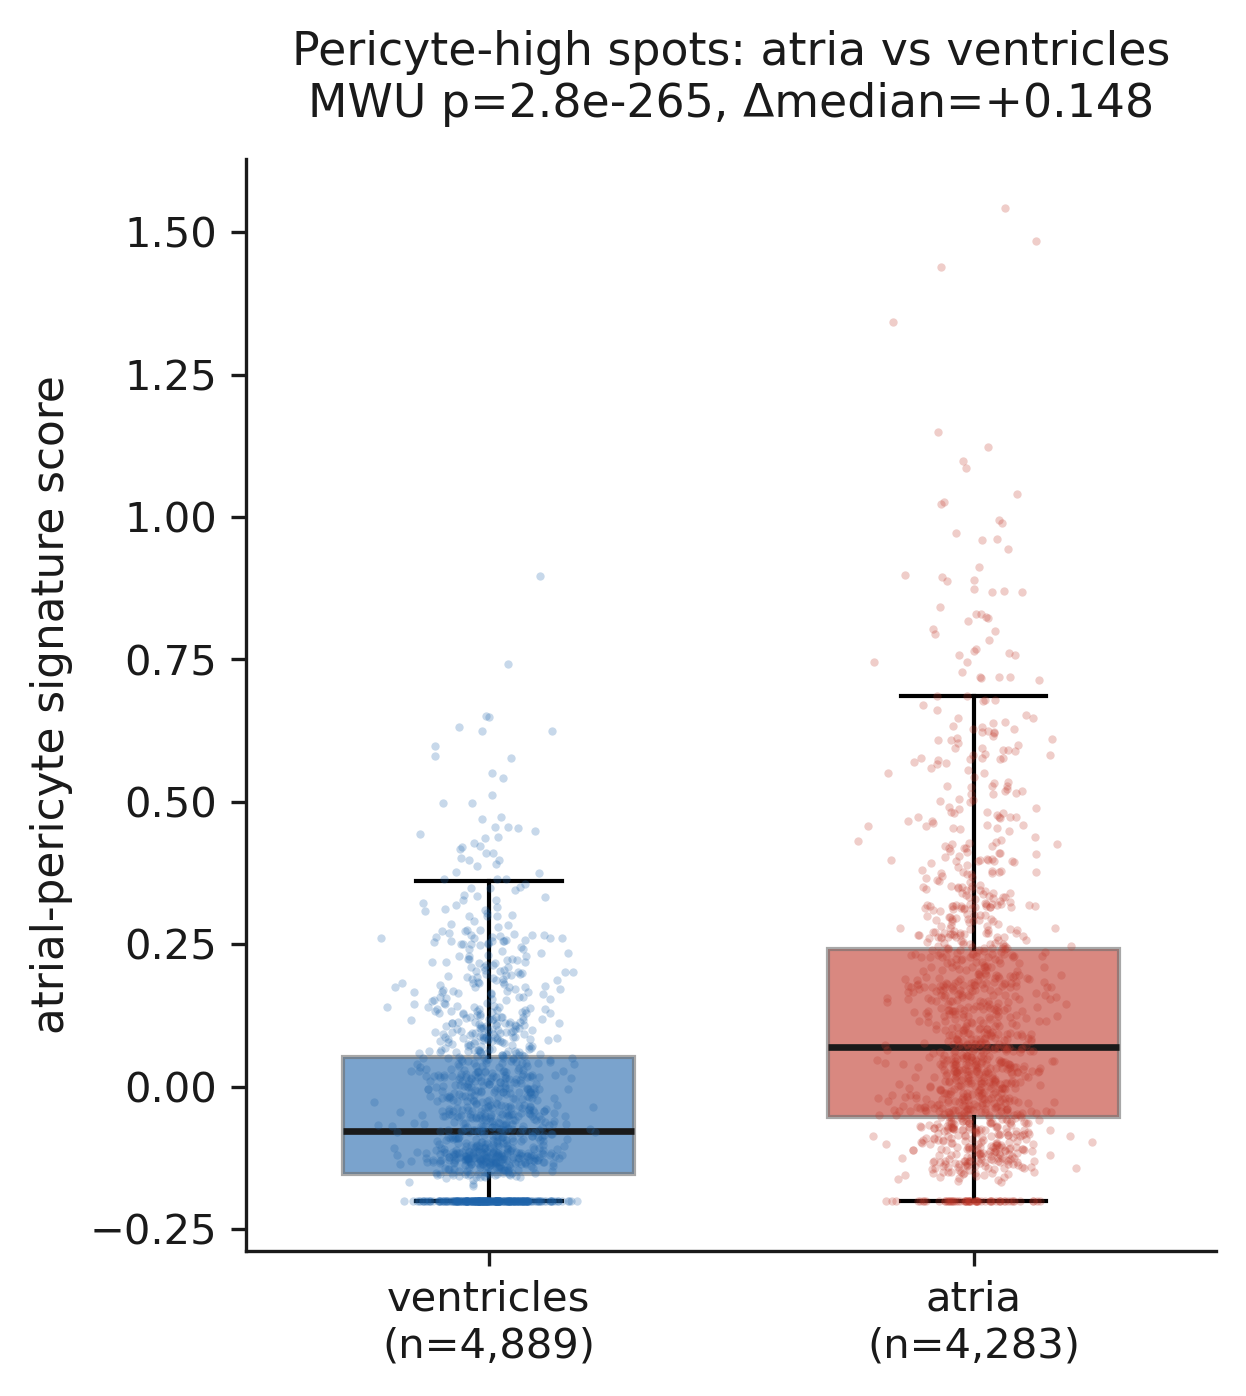

In [48]:
fig = hhca.pl.pericyte_signature(spots=pericyte_spots, show=["chambers"])

Of the 30 signature genes 29 are measured on Visium, and 27 of them are higher in the atria (not *DACH1* and
*NLGN1*). Within the atria the signature score is higher in pericyte-high than in pericyte-low spots (median 0.070
against −0.032, p = 2.4e-120), and among the pericyte-high spots it is higher in the 4,283 atrial than in the 4,889
ventricular spots (0.070 against −0.078, p = 2.8e-265). Each of the three donors with atria and ventricles shows
the same direction; with three donors the paired test cannot go below p = 0.25.

## Key takeaways

- Spots of known composition can be built from Visium HD by summing a section over 55 µm tiles; they turn the
  choice of a deconvolution method into a measurement.
- On these spots spotiphy is the most accurate of seven methods (RMSE 0.056 against 0.083 for RCTD and 0.135 for
  NNLS) and it is the best method on sections from all three positions of the wall.
- On real slides the methods differ most in the cardiomyocyte proportion (0.19 to 0.80), and NNLS, UCASpatial and
  stereoscope report immune and lymphatic cells at a constant background level.
- In the 45,536 cardiomyocyte-dominant spots of two cohorts all 17 chamber genes of the atlas follow their atrial
  or ventricular direction.
- Pericyte-high spots of the atria carry the atrial-pericyte signature more than those of the ventricles (median
  score 0.070 against −0.078), in each donor with both regions.
- Every step is one function of `hhca.tl` and every panel one function of `hhca.pl`, so the same code runs here
  and in the pipeline scripts.